# English Money/OTP Worker v2: data → labels → model → evaluation

**What this worker does:** for any sentence a caller says, it returns a score from 0 to 1: *is the caller **asking** for money, card or bank details, or a code?* The full rule is in `LABELING.md` (written by A6).

| Sentence | v1 target (mention) | **v2 target (ask)** |
|---|---|---|
| "Read me the OTP we sent you." | 1 | **1** |
| "Settle what you owe before 5pm." | 1 | **1** (no money keyword, still an ask) |
| "Your PayNow transfer was successful." | 1 | **0** (receipt, nothing asked) |
| "Never share your OTP with anyone." | 1 | **0** (warning) |
| "Please pay attention to this." | 0 | **0** (idiom) |
| "I'm calling from the police." | 0 | **0** (impersonation: another worker) |

**Why v2 (Workstream D):** v1 was trained on keyword labels, so it learned the keyword list. It flagged honest calls that mention money (4 of 5 normal demo calls scored 1.00) and missed scams that avoid the words ("settle what you owe" 0.002).

**Parts**

| Part | Does | Saves (in `CSC3104_money_otp/` on Drive) |
|---|---|---|
| A | Settings, shared code (`money_norm.py`, `money_model.py`), `LABELING.md`, Kaggle token | `code/` |
| B | Load the 8 sources into one table | `processed/B_*.csv` |
| C | Sentences → **ask-rule labels** → clean → de-duplicate → balance | `processed/C_*.csv` |
| D | Files for people: audit sample, **recheck sheet** for the test sets | `processed/D_*` |
| E | Write `train.py`, run it: TF-IDF + logistic regression, calibrate | `code/train.py`, `model/money_en_v2.*` |
| F, G | **v1 vs v2** on the same test sets, keyword-dependence test, probes, demo calls | `processed/F_*`, `processed/G_*`, `processed/before_after.csv` |

**Input files you keep in the main Drive folder** (made by people, the notebook only reads them):
`handwritten_train.csv`, `sg_gold.csv`, `D_ftc_labelled.csv`, `test_set_binary_classifier.csv`, `kaggle.json`.
Optional: `handwritten_extra.csv` (new D.3/D.4 training rows), `probes.csv`, `demo_calls_en.csv`,
`E_model_v1.joblib` (the frozen v1 model, for the before/after table), `recheck_labelled.csv` (filled-in recheck sheet).

**Order of use**
1. Run everything top to bottom.
2. Fill in `processed/D_recheck_to_label.csv` (only test sentences that were 1 under the old rule) and save it as **`recheck_labelled.csv` in the main folder**. Also fill in `D_audit_sample.csv`.
3. Run Parts F and G again: the before/after table now uses the new-rule labels.

**Checkpoints:** a part whose output files already exist is skipped. Put its letter in `FORCE_RERUN` to redo it.

# Part A: Setup

In [1]:
# scikit-learn is pinned to the version the money_en worker container uses (backend/workers/money_en/requirements.txt):
# a joblib model only loads reliably in the version that saved it.
!pip -q install datasets kaggle scikit-learn==1.6.1
import sklearn; print('scikit-learn', sklearn.__version__, '(must be 1.6.1; if not, Runtime > Restart session and run again)')

scikit-learn 1.6.1 (must be 1.6.1; if not, Runtime > Restart session and run again)


## A1. Settings
Everything you might change is here.

In [2]:
import os, re, json, glob, gzip, zipfile, hashlib, shutil, urllib.request
from collections import Counter
import numpy as np
import pandas as pd
from IPython.display import display

# ---- which parts to redo even if their files exist
FORCE_RERUN = ["C", "D"]                 # e.g. ["C"] or ["B", "C", "D", "E"]

# ---- sources
USE_MENDELEY = True              # set False to go ahead without the Mendeley data
KEEP_BOTH_SIDES = False          # v2: caller side only, like the live worker (the gateway only scores caller lines).
                                 # With both sides, ~160 victim/customer turns ("my account", "my card") were all 0s,
                                 # so v2 learned "my" -> not money and missed "transfer it to my account".
BOTHBOSU_SCAM_TYPES = ["ssn", "support", "refund", "reward"]
ABCD_FLOWS = ["purchase_dispute", "product_defect", "order_issue", "subscription_inquiry"]
SGD_SPLITS = {"train": 127, "dev": 20, "test": 34}
DAILYDIALOG_MAX_CONVS = 3000
MENDELEY_MAX_ROWS = 3000
OVERLAP_THRESHOLD = 0.90         # conversations this similar count as copies

# ---- sentences and balancing
MAX_WORDS, CHUNK_WORDS = 40, 20
NEG_PER_POS = 2                  # 0s per 1
POS_SOURCE_CAP = 0.40            # no source above 40% of the 1s
NEG_SOURCE_CAP = 0.40            # ... or of the 0s
SMS_MAX_SHARE = 0.25             # text-message sources at most 25% of each class
DAILYDIALOG_MAX_SHARE = 0.15
HARD_NEG_MAX_SHARE = 0.25        # word-sense 0s ("pay attention"): all kept, up to this share
MENTION_NEG_SHARE = 0.25         # v2: 0s that CONTAIN a money word but ask for nothing ("your transfer was successful").
                                 # Without them, "has a money word" would still predict the label perfectly.
ASK_NEG_SHARE = 0.20             # v2: 0s that ARE an ask but not for money ("can you send me the file", "please hold").
                                 # The mirror of mention 0s: without them "can you / please / tell me" alone predicts a 1.
SCAM_NEG_SHARE = 0.20            # 0s from scam calls (impersonation/urgency without an ask)
NEAR_DUP_THRESHOLD = 0.90
NEAR_DUP_POOL_PER_SOURCE = 12000 # max candidates per source and class before near-duplicate removal

# ---- training (passed to train.py)
CONFIGS = [                      # v2: word 1-2-grams only. Character 3-5-grams made "priceless" match "price"
    {"name": "word12_C0.3", "char": False, "C": 0.3},   # and "PayNow" match "pay" (v1's false alarms)
    {"name": "word12_C1",   "char": False, "C": 1.0},
    {"name": "word12_C3",   "char": False, "C": 3.0},
]
VAL_SHARE, CAL_SHARE = 0.15, 0.15   # by call group: 70% train, 15% choose model, 15% calibrate
HANDWRITTEN_WEIGHT = 10          # each hand-written sentence counts this many times in training
THRESHOLD = 0.5
MODEL_VERSION = "money_en_v2c"   # D.8: never reuse a version name; train.py refuses to overwrite an existing one
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

# ---- keyword-dependence test (D.2) and pass marks
HIDE_TOP_N = 20                  # hide each model's top-N words and score again
HIDDEN_AUC_MIN = 0.75            # pass: ROC-AUC with the words hidden stays at least this
HIDDEN_RECALL_KEEP = 0.5         # pass: recall on the 1s keeps at least half its original value
PLACEHOLDER_MAX_AUC = 0.70       # train.py drops placeholder tokens (moneytoken...) if they alone reach this ROC-AUC
MONEY_RULE_LINE = 0.7            # the aggregator's AGG_MONEY_RULE: a normal call must stay below this

## A2. Folders and checkpoints
On Colab, everything is saved straight to Drive, so it survives session resets.

In [3]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
    WORK_DIR = "/content/drive/MyDrive/CSC3104_money_otp"
except ImportError:
    IN_COLAB = False
    WORK_DIR = os.environ.get("MONEY_WORK_DIR", "money_otp_work")

RAW_DIR = os.path.join(WORK_DIR, "raw")
OUT_DIR = os.path.join(WORK_DIR, "processed")
MODEL_DIR = os.path.join(WORK_DIR, "model")
CODE_DIR = os.path.join(WORK_DIR, "code")
for d in (RAW_DIR, OUT_DIR, MODEL_DIR, CODE_DIR):
    os.makedirs(d, exist_ok=True)

def out(name):
    return os.path.join(OUT_DIR, name)

MODEL_PATH = os.path.join(MODEL_DIR, f"{MODEL_VERSION}.joblib")
PART_FILES = {
    "B": [out("B_master.csv"), out("B_ftc.csv"), out("B_sg_gold.csv")],
    "C": [out("C_train_pool.csv"), out("C_ftc_sentences.csv")],
    "D": [out("D_audit_sample.csv"), out("D_recheck_to_label.csv")],
    "E": [MODEL_PATH],
}

def need(part):
    """True if this part must run: forced, or any of its output files is missing (or B finished incomplete)."""
    missing = [f for f in PART_FILES[part] if not os.path.exists(f)]
    incomplete = False
    if part == "B" and not missing and os.path.exists(out("B_status.json")):
        incomplete = json.load(open(out("B_status.json"))).get("incomplete", False)
    run = part in FORCE_RERUN or bool(missing) or incomplete
    why = "forced" if part in FORCE_RERUN else "missing outputs" if missing else "last run incomplete" if incomplete else ""
    print(f"Part {part}: " + (f"RUN ({why})" if run else "SKIP (outputs exist; add to FORCE_RERUN to redo)"))
    return run

step_counts = []
def record(step, df):
    lab = df["label"] if "label" in df else pd.Series(dtype=float)
    step_counts.append({"step": step, "rows": len(df),
                        "label_1": int((lab == 1).sum()), "label_0": int((lab == 0).sum())})
    print(f"{step:<42} rows={len(df):>7}  1s={int((lab == 1).sum()):>6}  0s={int((lab == 0).sum()):>7}")

def input_path(fname):
    """A hand-made input file: next to the notebook or in the main Drive folder. None if missing."""
    for p in (fname, os.path.join(WORK_DIR, fname)):
        if os.path.exists(p):
            return p
    return None

# ---- input files made by people: the notebook reads them but can never re-create them
REQUIRED_INPUTS = {
    "handwritten_train.csv": "hand-written training sentences",
    "sg_gold.csv": "Singapore gold test set",
    "test_set_binary_classifier.csv": "200-sentence test set",
    "D_ftc_labelled.csv": "FTC sentences labelled by hand (v1 rule)",
}
OPTIONAL_INPUTS = {
    "handwritten_extra.csv": "new D.3/D.4 rows (mention-not-ask 0s, ask-without-keyword 1s)",
    "probes.csv": "hand-written probe sentences (F9)",
    "demo_calls_en.csv": "the app's English demo calls (F10)",
    "E_model_v1.joblib": "frozen v1 model, for the before/after table",
    "recheck_labelled.csv": "filled-in recheck sheet (new-rule labels for the test sets)",
}
print("Working folder:", WORK_DIR)
missing_required = [f for f in REQUIRED_INPUTS if input_path(f) is None]
for f, what in {**REQUIRED_INPUTS, **OPTIONAL_INPUTS}.items():
    print(f"  {'OK     ' if input_path(f) else ('MISSING' if f in REQUIRED_INPUTS else 'not yet')}  {f:<34} {what}")
if missing_required:
    raise FileNotFoundError(f"Put these in {WORK_DIR} first (they cannot be re-created): {missing_required}")

Mounted at /content/drive
Working folder: /content/drive/MyDrive/CSC3104_money_otp
  OK       handwritten_train.csv              hand-written training sentences
  OK       sg_gold.csv                        Singapore gold test set
  OK       test_set_binary_classifier.csv     200-sentence test set
  OK       D_ftc_labelled.csv                 FTC sentences labelled by hand (v1 rule)
  not yet  handwritten_extra.csv              new D.3/D.4 rows (mention-not-ask 0s, ask-without-keyword 1s)
  not yet  probes.csv                         hand-written probe sentences (F9)
  not yet  demo_calls_en.csv                  the app's English demo calls (F10)
  OK       E_model_v1.joblib                  frozen v1 model, for the before/after table
  OK       recheck_labelled.csv               filled-in recheck sheet (new-rule labels for the test sets)


## A3. Shared text code: `money_norm.py`
Training data, test data and the live worker all use **this one file**, so text is always processed the same way.

| Function | Does |
|---|---|
| `split_sentences` | Splits on `.` `!` `?` and new lines; pieces over 40 words become ~20-word chunks |
| `find_money_cues` | Returns **strong** cues (OTP, pay, PayNow, S$, fee, refund, gift card…), **weak** cues (account, card, code, bank, transfer…) and **not-money** phrases found |
| `NOT_MONEY` | Phrases removed *before* cue matching: "pay attention", "in charge", "transfer to the Circle Line"… **v2 adds** "pay heed / tribute / homage", "paid a compliment", "priceless", "the bill was passed", "hard work paid off" |
| `money_label` | **v1 keyword label**, kept only as the *keyword baseline* in Part F |
| **`request_label`** | **v2 label (LABELING.md):** an ask (`ASK_RE`) + a money cue or ask-object (`ASK_OBJECT_RE`: "the digits", "what you owe", "the notification on your app") → **1**; a warning ("never share…", "if anyone asks… hang up") → **0**; no ask → **0**; an ask about something only vaguely money ("check your account") → `None` (dropped). Victim/customer turns are never 1 |
| `request_parts` | What `request_label` saw, for checking a label by eye |
| `mentions_money` | True if a text has any strong cue (used per conversation in Part B) |
| `clean_text` | Amounts → `moneytoken`, OTP/PIN/CVV placeholders → `codetoken`, numbers → `numtoken`, lowercase, no punctuation. **v2: brand names → their type** (DBS → `orgbank`, PayNow → `payapp`), the same token names as `impersonation_en`. `mask_brands=False` = exactly v1's cleaning |
| `is_filler` | Under 3 real words and no cue ("uh okay") |
| `tag_topic` | otp, gift_card, refund, bank_transfer, investment, credit_card, prize, insurance, bill, loan, bank_account, other |

To change the rule, edit it here and re-run from Part C (`FORCE_RERUN = ["C", "D", "E"]`).

In [4]:
%%writefile money_norm.py
"""money_norm.py: shared text code for the English Money/OTP worker (v2).

Written by the notebook and imported by every later step (and later by the live worker),
so training data, test data and new sentences are always processed by the same code.

v2 changes (Workstream D):
  - request_label(): the label rule from LABELING.md. 1 only when the speaker ASKS the listener
    for money, card/bank details or a code. A money word alone ("never share your OTP",
    "your transfer was successful") is 0. money_label() is kept as the old keyword baseline.
  - clean_text(mask_brands=True): bank/shop/app names become their type (DBS -> orgbank,
    PayNow -> payapp), the same idea and token names as the impersonation_en worker.
    mask_brands=False reproduces v1's cleaning exactly (used to score the frozen v1 model).
  - more idioms in NOT_MONEY ("pay heed", "pay tribute", "priceless", "the bill was passed").
"""
import re
import unicodedata

# ---------------------------------------------------------------- splitting
SENT_END = re.compile(r"(?<=[.!?])\s+")
NEWLINES = re.compile(r"\s*\n+\s*")


def split_sentences(text, max_words=40, chunk_words=20):
    """Split a turn/call into sentences. Pieces longer than max_words are cut into ~chunk_words chunks."""
    out = []
    text = re.sub(r"([a-z][.!?])([A-Z])", r"\1 \2", str(text))   # "done.Then" -> "done. Then"
    for block in NEWLINES.split(text):
        for s in SENT_END.split(block):
            s = s.strip()
            if not s:
                continue
            words = s.split()
            if len(words) > max_words:
                for i in range(0, len(words), chunk_words):
                    out.append(" ".join(words[i:i + chunk_words]))
            else:
                out.append(s)
    return out


def light_norm(text):
    """Lowercase, straight quotes, single spaces."""
    t = str(text).replace("\u2019", "'").replace("\u2018", "'")
    t = t.replace("\u201c", '"').replace("\u201d", '"')
    return re.sub(r"\s+", " ", t).strip().lower()


# ------------------------------------------------------- not-money phrases
# Removed BEFORE cue matching, so "pay attention" or "transfer to the Circle Line" are not money.
NOT_MONEY = [
    r"pay(?:s|ing)? (?:close |more |full |special |extra )?attention",
    r"pay(?:s|ing)? (?:\w+ ){0,3}a visit",
    r"pay(?:s|ing)? (?:my |our |their |your |his |her )?respects",
    r"\bin charge\b",
    r"charg(?:e|es|ed|ing) (?:my|your|the|his|her|our) (?:phone|laptop|battery|device|tablet|car)",
    r"(?:phone|laptop|battery|device) (?:needs|need|is|was) (?:to )?(?:be )?charg\w*",
    r"\bneeds? to charge\b", r"\bchargers?\b",
    r"into account", r"on account of",
    r"(?:instagram|facebook|tiktok|twitter|google|email|e-mail|gmail|social media|school|student|game|gaming|user) accounts?",
    r"accounts? on (?:instagram|facebook|tiktok|twitter|x)\b",
    r"dress code", r"code of conduct", r"(?:source|programming|python|java) code",
    r"(?:write|writing|wrote|written|run|running|debug|debugging|fix|fixing|test|testing) (?:the |my |this |some |your |our )?code",
    r"transfer(?:s|red|ring)? (?:to|at) (?:the )?(?:[\w-]+ ){0,3}(?:line|station|interchange|mrt|lrt|bus|train)",
    r"transfer(?:s|red|ring)? (?:you|your call|the call|this call|calls?)\b",
    r"transfer(?:s|red|ring)? (?:to|from) (?:another|a different|a new) (?:school|department|team|class|unit|branch|office)",
    r"credit (?:goes|to the team|where)", r"give (?:\w+ )?(?:some )?credit", r"course credits?", r"(?:extra|bonus) credits?",
    r"river ?bank", r"bank of the (?:river|reservoir|lake|canal|stream)", r"(?:food|blood) bank",
    r"(?:lost|lose|losing|no|any|little|much|great|keen|an|my|his|her|their|special) interest in",
    r"\binterest(?:ed|ing)\b",
    r"\bpin(?:ned|ning|s)? (?:the |this |that |it |a |my |your )?(?:\w+ )?(?:location|message|post|address|place)",
    r"(?:balance|balancing) (?:work|life|school|study|studies|between|it|things|my|your)",
    r"(?:lost|lose|keep|keeping) (?:my |his |her |your )?balance", r"work-life balance",
    r"(?:thank[- ]you|birthday|greeting|christmas|festive|sim|identity|id|business|report|game|playing|memory|sd|graphics|name|library|student) cards?",
    r"token of (?:appreciation|thanks|gratitude|love)",
    r"(?:school|student|portal|email|e-mail|wifi|wi-fi|computer|laptop|instagram|facebook|game) (?:login|password)s?",
    r"password for (?:the |your |my )?(?:school|student|portal|email|e-mail|wifi|wi-fi|computer|laptop)",
    # v2: idioms that the v1 model flagged as money (test-set false alarms)
    r"pa(?:y|ys|id|ying) (?:\w+ )?(?:heed|tribute|homage|lip service)",
    r"pa(?:y|ys|id|ying) (?:\w+ )?(?:a |the |my |his |her |some )?compliments?",
    r"pa(?:y|ys|id|ying) (?:a |the )?(?:heavy |high |big )?price for",
    r"(?:it|that|this|which|work|effort|efforts|practice|training|patience) (?:\w+ )?(?:will |has |have |had |really |finally |all )?pa(?:y|ys|id) off",
    r"\bpriceless\b", r"\bbill (?:was|is|has been) (?:passed|tabled|debated|read)", r"pass(?:ed|es|ing)? the bill",
    r"invest(?:s|ed|ing)? (?:\w+ )?(?:time|effort|energy|attention)",
    r"(?:time|attention|focus) (?:well |wisely )?spent",
    r"(?:room|meeting|zoom|locker|postal|zip|door|gate|wifi|wi-fi|promo|promotion|discount|referral|invite|invitation|class|course|module|booking|tracking|qr) codes?(?! (?:we|i|that|which|sent|from (?:the |your )?(?:bank|sms)))",
    r"drop (?:a |the |me a )?pin", r"social security (?:numbers?|cards?|administration|office|benefits?|payments?|account)", r"(?:files?|photos?|pictures?|data|documents?|videos?|contacts?|folder) (?:to|into|onto|over)",
]

# ------------------------------------------------------------ money cues
STRONG = [
    # amounts and currency
    r"(?:s\$|us\$|\$|\u00a3|\u20ac|\u00a5)\s?\d",
    r"\b\d[\d,]*(?:\.\d+)?\s?(?:k )?(?:dollars?|bucks|cents?|sgd|usd|yuan|rmb|ringgit|pounds|euros?)\b",
    r"\b(?:dollars?|bucks|sgd|usd|rmb)\b",
    # OTP and banking credentials
    r"\botps?\b", r"one[- ]time (?:password|pin|passcode|code)",
    r"(?:verification|security|authentication|sms) codes?",
    r"\b(?:four|five|six|4|5|6)[- ]digit (?:code|pin|number|otp)",
    r"\btac\b", r"\bpasscodes?\b", r"digital token", r"two[- ]factor|\b2fa\b",
    r"\bcvv\b|\bcvc\b", r"card (?:number|details|expiry)", r"\bpin (?:number|code)\b",
    r"(?:internet|online|mobile) banking",
    r"bank(?:ing)? (?:login|password|details|account details|account number|username)",
    r"account number",
    # paying and moving money
    r"\bpay(?:s|ing|ment|ments|able|out)?\b", r"\bpaid\b", r"\brepa(?:y|id)\w*",
    r"\bpaynow\b", r"\bpaylah\b", r"\bpaypal\b", r"\bgiro\b", r"\bvenmo\b|\bzelle\b",
    r"\bmoney\b", r"\bcash(?:back)?\b", r"\bcheques?\b", r"\bfunds?\b", r"\bsavings\b",
    r"\bsalar(?:y|ies)\b", r"\bwages?\b", r"\bloans?\b", r"\bdebts?\b",
    r"\bdeposit(?:s|ed|ing)?\b", r"\bwithdraw(?:al|als|n|ing|s)?\b",
    r"\bfees?\b", r"\b(?:outstanding|overdue|unpaid) (?:fine|amount|balance|bill|payment|sum|charges?)\b", r"\bfine of\b",
    r"\brefund\w*", r"\breimburs\w*", r"\brebates?\b",
    r"\binvest(?:s|ed|ing|ment|ments|or|ors)?\b", r"\bprofits?\b", r"\bdividends?\b", r"\bcrypto\w*", r"\bbitcoin\b", r"\bforex\b",
    r"\btrading (?:platform|account|app)\b",
    r"gift ?cards?", r"(?:google play|itunes|apple|steam|amazon|razer) (?:gift )?cards?", r"\bvouchers?\b",
    r"\btop[- ]?up\b", r"\bpremiums?\b", r"\btax(?:es)?\b", r"\binvoices?\b", r"\bpurchas\w*",
    r"\bprices?\b", r"\bcost(?:s|ing)?\b", r"\bhow much (?:is|was|does|did|do|for|money|to pay|are)\b",
    r"(?:credit|debit|atm|bank|ez-link|nets) cards?", r"(?:account|card) balance", r"\bbalance (?:is|of)\b",
    r"\binterest (?:rate|will be|of|earned|charged|payment)",
    r"(?:electricity|phone|water|utility|utilities|credit card|monthly|medical|hospital|mobile|internet|telco) bills?",
    r"\bbills? (?:for|of|is due|amount|payment)\b",
    r"\b(?:bank|wire|fund|money|telegraphic) transfers?\b",
    r"transfer(?:s|red|ring)? (?:the |your |my |this |that |all )?(?:money|funds|amount|savings|sum|payment)",
    r"\bcpf\b", r"\bmedisave\b", r"\bang ?(?:bao|pao)\b", r"\bhongbao\b", r"\bred packets?\b",
    r"\bsafe account\b", r"\be-?wallets?\b",
]
WEAK = [
    r"\baccounts?\b", r"\bcards?\b", r"\bcodes?\b", r"\bbank(?:s|ing)?\b", r"\bcharg(?:e|es|ed|ing)\b",
    r"\btransfer(?:s|red|ring)?\b", r"\bbalance\b", r"\bcredit(?:s|ed)?\b", r"\binterest\b", r"\bpin\b",
    r"\bbills?\b", r"\btokens?\b", r"\bpasswords?\b", r"\blog ?in\b", r"\bcommissions?\b", r"\bqr\b",
]
NOT_MONEY_RE = re.compile("|".join(f"(?:{p})" for p in NOT_MONEY))
STRONG_RE = re.compile("|".join(f"(?:{p})" for p in STRONG))
WEAK_RE = re.compile("|".join(f"(?:{p})" for p in WEAK))


def find_money_cues(text):
    """Cues in a sentence: {'strong': [...], 'weak': [...], 'not_money': [...]}."""
    t = light_norm(text)
    not_money = [m.group(0) for m in NOT_MONEY_RE.finditer(t)]
    t = NOT_MONEY_RE.sub(" ", t)
    return {"strong": [m.group(0) for m in STRONG_RE.finditer(t)],
            "weak": [m.group(0) for m in WEAK_RE.finditer(t)],
            "not_money": not_money}


def money_label(text):
    """Keyword label: 1 if a strong cue, None if only weak cues (unclear), else 0."""
    c = find_money_cues(text)
    if c["strong"]:
        return 1
    if c["weak"]:
        return None
    return 0


def mentions_money(text):
    return bool(STRONG_RE.search(NOT_MONEY_RE.sub(" ", light_norm(text))))


# ------------------------------------------------- v2: the request rule (LABELING.md)
# 1 = the speaker ASKS the listener to pay / transfer / buy / top up, or to give card or bank
#     details, an OTP / PIN / code, or to approve a payment or login.
# 0 = no ask: warnings, receipts, prices and bills stated as facts, stories, idioms, questions.
# None = an ask whose object is too vague to judge ("check your account"): dropped, like v1's weak-only rows.
LABEL_RULE_VERSION = "money_en_rule_v2 (2026-11-01)"

_EXPAND = [(re.compile(r"\bwon't\b"), "will not"), (re.compile(r"\bcan't\b"), "cannot"),
           (re.compile(r"\bdon't\b"), "do not"), (re.compile(r"\bdoesn't\b"), "does not"),
           (re.compile(r"\bdidn't\b"), "did not"), (re.compile(r"\bisn't\b"), "is not"),
           (re.compile(r"\bi'm\b"), "i am"), (re.compile(r"\bi'll\b"), "i will"),
           (re.compile(r"\bwe'll\b"), "we will"), (re.compile(r"\byou'll\b"), "you will"),
           (re.compile(r"\bwhat's\b"), "what is"), (re.compile(r"\bn't\b"), " not")]

ASK_VERBS = (r"send|pay|transfer|wire|remit|lend|loan me|reimburse|repeat|invest|paynow|paylah|bring|pass (?:it|them|the \w+) to|give|hand (?:over|me)|pass me|tell|read(?: out)?|share|provide|"
             r"confirm|key(?: it)? in|enter|type(?: in)?|input|fill in|approve|authori[sz]e|accept|verify|"
             r"buy|purchase|get me|top(?:[- ]?up)?|deposit|withdraw|move|put|drop|bank in|settle|clear|"
             r"scan|click|tap|press (?:approve|yes|accept|ok|confirm)|download|install|log ?in(?:to)?|sign ?in|go (?:to|down to)|head to|"
             r"open|forward|screenshot|snap|take a (?:photo|picture)|let me (?:have|know)|make (?:the |a )?payment|"
             r"cash out|redeem|transact|make (?:a |the )?transfer")
# imperative at the start of a clause (after "please", "and", "then", "now", "just", "ok" ...)
_LEAD = r"(?:^|[,;:]\s*|\b(?:and|then|so|now|just|first|next|quickly|please|pls|kindly|ok|okay|alright|sir|madam|maam|auntie|uncle|boss|lah)\s+)"
ASK_RE = re.compile("|".join([
    _LEAD + r"(?:please |pls |kindly |just |quickly |also )?(?:" + ASK_VERBS + r")\b",
    r"\b(?:you|u|ya)\s+(?:will |would |also |just |still |first |now )?(?:need|needs|have|has|must|got|gotta|are required|are going to have)\s+(?:to\s+)?(?:" + ASK_VERBS + r")\b",
    r"\b(?:you|u)\s+(?:must|should|have to|need to|can|could)\s+(?:quickly |first |now )?(?:" + ASK_VERBS + r")\b(?=.*\b(?:now|today|immediately|first|before|or else|otherwise|quickly)\b)",
    r"\b(?:can|could|would|will) (?:you|u) (?:please |kindly |just |quickly )?(?:" + ASK_VERBS + r")\b",
    r"\b(?:i|we) (?:will |would |just |also |still )?(?:need|require) (?:you to|your|the|that|this)\b",
    r"\b(?:is|are) (?:needed|required)\b(?! for (?:the|your) (?:meeting|event|class|appointment))",
    r"\b(?:i|we) (?:will |would |just |also |still )?need to (?:see|have|get|verify|confirm|know|take) your\b",
    r"\b(?:would|do) (?:you|u) (?:like|want|wish) to (?:" + ASK_VERBS + r")\b",
    r"\b(?:if|unless) (?:you|u) (?:do not |did not |fail to |refuse to |cannot |still )?(?:" + ASK_VERBS + r")\b",
    r"\b(?:may|can|could) (?:i|we) (?:please )?(?:have|get|know|take|confirm|verify)\b",
    r"\bwhat (?:is|are|was|were|did) (?:\w+ ){0,4}(?:otp|pin|code|password|card|account|cvv|numbers?|digits)\b",
    r"\b(?:otp|pin|code|tac|passcode),? what is it\b",
    r"^what (?:otp|pin|code|tac|numbers?|digits)\b",
    r"\b(?:when|which month|what (?:is|are|was) the) (?:\w+ ){0,8}?(?:expir\w*|expiry)\b",
    r"\b(?:it is|you are) (?:required|necessary|mandatory) (?:to|that you)\b",
    r"\b(?:need|required) to (?:pay|transfer|make (?:a |the )?payment|settle|clear)\b(?!.*\b(?:i|we) need to\b)",
    r"\bpress (?:\w+ )?(?:to|and) (?:pay|make|settle|clear|confirm|authori[sz]e|approve)\b",
    r"\b(?:otp|pin|code|card number|cvv|account number|payment|the amount|the money)\s*,?\s*(?:please|pls)\s*[.!?]?\s*$",
]))
# objects an ask can be about, beyond the STRONG money cues
ASK_OBJECT_RE = re.compile("|".join([
    r"\b(?:\w+[- ])?digits?\b", r"\bnumbers? (?:that|which|we|i|you|on|from|in|at|sent|texted)\b",
    r"\b(?:the|those|these|six|four|\w+-digit) numbers\b", r"\b(?:verification|security|reference|card|pin|otp|tac|six-digit|\d-digit) numbers?\b",
    r"\b(?:a few |some |one |two |three |five |\w+ )?(?:hundred|thousand|grand)\b", r"\bsome (?:cash|money)\b",
    r"\b(?:bank |the )?sms\b", r"\b(?:the |a )?deposit\b", r"\b(?:the |a )?penalty\b",
    r"\b(?:the |that |this |your )?codes?\b", r"\bpins?\b", r"\bpasswords?\b", r"\bcards?\b",
    r"\bwhat (?:you|u) owe\b", r"\b(?:outstanding )?dues\b", r"\bowe\b", r"\barrears\b", r"\bthe (?:full |remaining )?(?:amount|sum|balance)\b",
    r"\b(?:into|to|in) (?:the|this|my|our|a|that|another|new|safe|holding|secure|following) (?:\w+ )?accounts?\b",
    r"\baccount (?:details|info|information|number|login|password)\b",
    r"\b(?:notification|prompt|request|transaction|login|log-in|authori[sz]ation|approval)\b",
    r"\b(?:singpass|banking|bank) app\b", r"\b(?:card|visa|mastercard)\b.*\b(?:expir\w*|expiry)\b|\b(?:expir\w*|expiry)\b.*\b(?:card|on it|visa|mastercard)\b", r"\bqr\b", r"\batms?\b", r"\bgift\b",
    r"\b(?:everything|all of it|all your savings|the rest)\b",
]))
# warnings, refusals and "no need to pay": never a 1
WARNING_RE = re.compile("|".join([
    r"\b(?:never|not|no|do not|does not|did not|will not|would not|cannot|should not|must not|don't|dont)\s+(?:\w+\s+){0,3}?(?:" + ASK_VERBS + r"|ask|asks|asking|request|need)\b",
    r"\bno need (?:to|for)\b", r"\bnothing to pay\b", r"\bfree of charge\b",
    r"\bbeware\b", r"\bscam(?:s|mer|mers)?\b", r"\bscamshield\b", r"\bfraud(?:ster|sters)?\b(?=.*\b(?:never|not|careful|report|beware|hang up)\b)",
    r"\bif (?:anyone|someone|somebody|they|a caller|the caller|anybody) (?:\w+ ){0,3}(?:ask|asks|calls|requests|tells)\b",
    r"\bhang up\b", r"\breport (?:it|this|them) to\b", r"\bbe careful\b", r"\bstay alert\b",
]))
# questions and statements that start like an ask but are not one ("why do you need my OTP?")
NOT_ASK_RE = re.compile(r"^(?:why|how come|how did|what for|who|did|have|has|were|was)\b"
                        r"|^(?:(?:but|and|ok|okay|yes|sorry|no),? )?(?:i|we) (?:already|just) (?:paid|sent|transferred|gave)\b"
                        r"|\bgive me (?:a |one )?(?:moment|minute|min|second|sec|call|chance|break)\b"
                        # routine reminders through the usual channel (LABELING.md edge case)
                        r"|\b(?:before|by|on) (?:the|its|your) due date\b|\b(?:upon|on|at) delivery\b|\bwhen it arrives\b"
                        r"|\bwhen (?:you )?(?:pick (?:it |them )?up|collect)\b")
IF_NOT_RE = re.compile(r"\b(?:if|unless) (?:you|u) (?:do not|did not|does not|cannot|will not|fail to|refuse to)\b")
LISTENER_SPEAKERS = {"victim", "receiver", "customer"}


def _expand(text):
    t = light_norm(text)
    for rx, rep in _EXPAND:
        t = rx.sub(rep, t)
    return t


# Money words that are only CONTEXT in an ask ("to validate your purchase, can I have your username?",
# "10% off your next purchase"): they say what the call is about, not what is being asked for. An ask whose only
# money words are these is left unlabelled (None) instead of 1. "Pay for your purchase" still counts through "pay".
CONTEXT_ONLY_RE = re.compile(r"^(?:purchas\w*|prices?|costs?|costing|invoices?|tax(?:es)?|premiums?|refund\w*|reimburs\w*|"
                             r"rebates?|vouchers?|cashback|cash back|profits?|dividends?|salar\w*|wages?|savings|loans?|"
                             r"debts?|how much .*|interest .*|.* bills?|bills? .*|(?:account|card) balance|balance (?:is|of))$")


def request_parts(text):
    """What request_label sees: {'ask': bool, 'warning': bool, 'strong': [...], 'object': [...]}."""
    t = _expand(text)
    t_money = NOT_MONEY_RE.sub(" ", t)
    strong = [m.group(0) for m in STRONG_RE.finditer(t_money)]
    obj = [m.group(0) for m in ASK_OBJECT_RE.finditer(t_money)]
    weak = [m.group(0) for m in WEAK_RE.finditer(t_money)]
    # the ask is searched with idioms removed ("please pay attention" is not an ask) ...
    ask = bool(ASK_RE.search(t_money)) and not NOT_ASK_RE.search(t)
    # ... and the warning check ignores threats like "if you do not pay ..." (those are pressure to pay, not advice)
    warning = bool(WARNING_RE.search(IF_NOT_RE.sub(" ", t)))
    action = [w for w in strong if not CONTEXT_ONLY_RE.match(w)]     # money words that can BE the thing asked for
    return {"ask": ask, "warning": warning, "strong": strong, "action": action, "object": obj, "weak": weak}


def request_label(text, speaker=None):
    """LABELING.md rule: 1 = speaker asks for money / card or bank details / a code; 0 = no ask; None = unclear.

    speaker: listener-side turns (victim, receiver, customer) are never 1: an ask from them is dropped (None),
    because the live worker only scores the caller and "can you refund me" from a customer is not a scam signal.
    """
    p = request_parts(text)
    if p["warning"]:
        return 0
    if p["ask"] and (p["action"] or p["object"]):
        return None if speaker in LISTENER_SPEAKERS else 1
    if p["ask"] and (p["strong"] or p["weak"]):
        return None          # "check your account", "can I have your username to validate your purchase": an ask,
                             # but not FOR money / details / a code: too unclear to label
    return 0


# ------------------------------------------------------------------ cleaning
PLACEHOLDER = re.compile(r"\[([A-Za-z_ ]{2,40})\]")


def _placeholder(m):
    k = m.group(1).upper()
    if any(w in k for w in ("MONEY", "AMOUNT", "PRICE", "BALANCE")):
        return " moneytoken "
    if any(w in k for w in ("OTP", "PIN", "CVV", "TAC", "PASSCODE", "PASSWORD", "CODE")):
        return " codetoken "
    if any(w in k for w in ("ORG", "COMPANY", "BUSINESS")):
        return " orgtoken "
    if "NAME" in k:
        return " nametoken "
    if any(w in k for w in ("DATE", "BIRTH", "DOB")):
        return " datetoken "
    if "PHONE" in k:
        return " phonetoken "
    if any(w in k for w in ("EMAIL", "URL", "WEBSITE", "LINK")):
        return " linktoken "
    if any(w in k for w in ("ADDRESS", "LOCATION", "CITY", "ZIP", "POSTAL", "STREET")):
        return " loctoken "
    if "CARD" in k:
        return " cardtoken "
    if any(w in k for w in ("ACCOUNT", "NUMBER", "SSN", "ID")):
        return " numtoken "
    if any(w in k for w in ("TIME", "DURATION")):
        return " timetoken "
    return " "


MONTHS = (r"(?:january|february|march|april|may|june|july|august|september|october|"
          r"november|december|jan|feb|mar|apr|jun|jul|aug|sep|sept|oct|nov|dec)")
CLEAN_STEPS = [
    (re.compile(r"\S+@\S+\.\S+"), " linktoken "),
    (re.compile(r"(?:https?://|www\.)\S+", re.I), " linktoken "),
    (re.compile(r"\b[\w-]+\.(?:com|net|org|sg|gov|io|co|info|biz)\b\S*", re.I), " linktoken "),
    (re.compile(r"(?:s\$|us\$|\$|\u00a3|\u20ac|\u00a5|\bsgd|\busd|\brm)\s?\d[\d,]*(?:\.\d+)?"
                r"(?:\s?(?:k|m|million|billion|thousand)\b)?", re.I), " moneytoken "),
    (re.compile(r"\b\d[\d,]*(?:\.\d+)?\s?(?:dollars?|bucks|yuan|rmb|cents?|sgd|usd|"
                r"ringgit|pounds?|euros?)\b", re.I), " moneytoken "),
    (re.compile(r"\b(?:\d[ -]?){12,19}\b"), " cardtoken "),
    (re.compile(r"(?:\+?\d{1,3}[\s-]?)?\(?\d{3}\)?X?[\s.-]?\(?\d{3}\)?X?[\s.-]?\(?\d{4}\)?"), " phonetoken "),
    (re.compile(r"\b[689]\d{3}\s?\d{4}\b"), " phonetoken "),
    (re.compile(r"\b\d{1,2}(?:st|nd|rd|th)?\s+(?:of\s+)?" + MONTHS + r"\b\.?(?:,?\s+\d{4})?", re.I), " datetoken "),
    (re.compile(r"\b" + MONTHS + r"\.?\s+\d{1,2}(?:st|nd|rd|th)?(?:,?\s+\d{4})?\b", re.I), " datetoken "),
    (re.compile(r"\b\d{1,4}[/-]\d{1,2}[/-]\d{2,4}\b"), " datetoken "),
    (re.compile(r"\b\d{1,2}(?::\d{2})?\s?(?:am|pm|a\.m\.|p\.m\.)", re.I), " timetoken "),
    (re.compile(r"\b\d+(?:st|nd|rd|th)\b", re.I), " numtoken "),
    (re.compile(r"\d+(?:[.,]\d+)*"), " numtoken "),
]
CONTRACTIONS = [
    (re.compile(r"\bwon't\b"), "will not"), (re.compile(r"\bcan't\b"), "cannot"),
    (re.compile(r"\bshan't\b"), "shall not"), (re.compile(r"n't\b"), " not"),
]
REPEATED_TOKEN = re.compile(r"\b(\w+token)(?:\s+\1\b)+")

# v2 (D.5): names become their TYPE so the model learns "asks you to pay via a payment app", not a list of brands.
# Token names match impersonation_en/text_utils.py ORG_TYPES (orgbank, orggovt, ...), plus payapp for payment apps.
# Differences from impersonation, on purpose: plain "grab" is left alone (usually the verb), "cpf" is left alone
# (CPF savings are money talk), "mom" is left alone ("send it to my mom"), and PayPal is a payapp here
# (impersonation calls it orgtech).
BRAND_TYPES = {
    "payapp": ["paynow", "paylah", "paylah!", "grabpay", "grab pay", "paypal", "venmo", "zelle", "cash app", "cashapp",
               "revolut", "youtrip", "shopeepay", "alipay", "wechat pay", "apple pay", "google pay", "nets pay"],
    "orgbank": ["dbs", "ocbc", "uob", "posb", "citibank", "citi", "hsbc", "standard chartered", "standard chartered bank",
                "maybank", "trust bank", "gxs", "bank of china", "icbc"],
    "orgpolice": ["spf", "singapore police force", "interpol"],
    "orggovt": ["ica", "iras", "mas", "singpass", "irs", "immigration and checkpoints authority",
                "monetary authority of singapore", "ministry of manpower", "inland revenue authority of singapore",
                "cyber security agency", "state courts", "supreme court", "ministry of home affairs",
                "ministry of health", "hdb", "lta", "csa", "govtech", "moh", "town council", "singapore customs", "mha"],
    "orgtelco": ["singtel", "starhub", "m1"],
    "orgtech": ["microsoft", "apple", "google", "amazon"],
    "orgcourier": ["singpost", "dhl", "fedex", "ninja van"],
    "orgshop": ["lazada", "shopee", "carousell", "taobao", "qoo10", "gojek"],
    "orgutility": ["sp group", "sp services"],
}
_BRAND_TO_TYPE = {n: t for t, names in BRAND_TYPES.items() for n in names}
# v2 cleaning: amounts written as words become moneytoken too, so "transfer fifty dollars" looks like "transfer $50"
_NUMW = (r"(?:a|one|two|three|four|five|six|seven|eight|nine|ten|eleven|twelve|thirteen|fourteen|fifteen|sixteen|"
         r"seventeen|eighteen|nineteen|twenty|thirty|forty|fifty|sixty|seventy|eighty|ninety|hundred|thousand|million|"
         r"and|numtoken)")
WORD_MONEY_RE = re.compile(r"\b(?:" + _NUMW + r"[ -]){1,6}(?:dollars?|bucks|sgd|ringgit)\b"
                           r"|\bnumtoken ?(?:k|grand)\b|\b(?:a|one|two|three|five|ten) grand\b")
BRAND_RE = re.compile(r"\b(" + "|".join(re.escape(n) for n in sorted(_BRAND_TO_TYPE, key=len, reverse=True)) + r")(?![\w])")


def mask_brands(t):
    """Lower-case text in, brand names replaced by their type token."""
    return BRAND_RE.sub(lambda m: _BRAND_TO_TYPE[m.group(1)], t)


def clean_text(text, mask_brands=True):
    """Full clean used for TF-IDF. Keeps stopwords, no stemming.
    mask_brands=True is the v2 cleaning: brand names -> type tokens, and written amounts ("fifty dollars", "2k")
    -> moneytoken. mask_brands=False gives exactly the v1 cleaning (needed to score the frozen v1 model fairly)."""
    t = str(text)
    t = PLACEHOLDER.sub(_placeholder, t)
    t = re.sub(r"<[^>]+>", " ", t)
    for rx, rep in CLEAN_STEPS:
        t = rx.sub(rep, t)
    t = unicodedata.normalize("NFKD", t).encode("ascii", "ignore").decode()
    t = light_norm(t)
    if mask_brands:                                            # v2 cleaning (v1 models keep v1's exactly)
        t = BRAND_RE.sub(lambda m: _BRAND_TO_TYPE[m.group(1)], t)
        t = WORD_MONEY_RE.sub(" moneytoken ", t)
    for rx, rep in CONTRACTIONS:
        t = rx.sub(rep, t)
    t = t.replace("'", "")
    t = re.sub(r"[^a-z\s]", " ", t)
    t = REPEATED_TOKEN.sub(r"\1", t)
    return re.sub(r"\s+", " ", t).strip()


FILLER = {"uh", "um", "umm", "hmm", "mm", "mhm", "ok", "okay", "yeah", "yes", "yep", "no", "nope",
          "hello", "hi", "hey", "thanks", "thank", "you", "bye", "goodbye", "alright", "right",
          "sure", "oh", "ah", "so", "well", "the", "a", "and", "is", "it", "that", "i", "im"}


def is_filler(clean, has_cue):
    """True if a sentence is too empty to teach anything: under 3 real words and no cue."""
    real = [w for w in clean.split() if not w.endswith("token") and w not in FILLER and len(w) > 1]
    return len(real) < 3 and not has_cue


# -------------------------------------------------------------------- topics
TOPICS = [
    ("otp", r"\botp\b|codetoken|verification code|one time password|\btac\b|digital token|security code|passcode"),
    ("gift_card", r"gift ?cards?|vouchers?|google play|itunes|steam cards?|redeem"),
    ("refund", r"refund|reimburs|money back|cashback|rebate"),
    ("bank_transfer", r"transfer|wire|paynow|paylah|remit|safe account|send (?:the )?money|western union"),
    ("investment", r"invest|portfolio|stocks?|crypto|bitcoin|trading|dividend|profit"),
    ("credit_card", r"credit card|debit card|card number|cvv|cardtoken|\bcard\b"),
    ("prize", r"prize|\bwon\b|winner|lottery|reward|congratulations"),
    ("insurance", r"insurance|policy|claim|coverage|premium"),
    ("loan", r"\bloans?\b|\bdebts?\b|borrow|lend|owe"),
    ("bill", r"\bbill|invoice|payment|overdue|subscription|charge|\bfees?\b|giro|tax"),
    ("bank_account", r"\bbank|account|\bpin\b|password|balance|savings|cpf|salary"),
]
TOPIC_RE = [(name, re.compile(rx)) for name, rx in TOPICS]


def tag_topic(clean):
    for name, rx in TOPIC_RE:
        if rx.search(clean):
            return name
    return "other"

Writing money_norm.py


In [5]:
import importlib, money_norm
importlib.reload(money_norm)
from money_norm import (split_sentences, light_norm, find_money_cues, money_label, mentions_money,
                        request_label, request_parts, clean_text, is_filler, tag_topic, LABEL_RULE_VERSION)
shutil.copy("money_norm.py", CODE_DIR)

print(LABEL_RULE_VERSION)
print(f"{'sentence':<62} {'v1 keyword':>10} {'v2 ask rule':>11}")
for s in ["Please read me the six-digit OTP we sent.", "Settle what you owe before five o'clock.",
          "Approve the notification on your Singpass app now.", "Your PayNow transfer of S$50 was successful.",
          "Never share your OTP with anyone.", "Please pay heed to the safety briefing.",
          "Transfer to the Circle Line at Dhoby Ghaut.", "This is Sergeant Lim from the police."]:
    print(f"{s:<62} {money_label(s)!s:>10} {request_label(s)!s:>11}")
print("\nclean_text v2:", clean_text("Transfer S$500 via PayNow to your DBS account."))
print("clean_text v1:", clean_text("Transfer S$500 via PayNow to your DBS account.", mask_brands=False))

money_en_rule_v2 (2026-11-01)
sentence                                                       v1 keyword v2 ask rule
Please read me the six-digit OTP we sent.                               1           1
Settle what you owe before five o'clock.                                0           1
Approve the notification on your Singpass app now.                      0           1
Your PayNow transfer of S$50 was successful.                            1           0
Never share your OTP with anyone.                                       1           0
Please pay heed to the safety briefing.                                 0           0
Transfer to the Circle Line at Dhoby Ghaut.                             0           0
This is Sergeant Lim from the police.                                   0           0

clean_text v2: transfer moneytoken via payapp to your orgbank account
clean_text v1: transfer moneytoken via paynow to your dbs account


## A4. Model wrapper: `money_model.py`
Holds the trained pipeline plus its calibration, and gives one simple interface:

| Method | Returns |
|---|---|
| `score(text)` | One number 0–1 for one sentence |
| `clean(text)` | The cleaning this model was trained with (v1: no brand masking, v2: masking). This is how the frozen v1 still scores exactly as before |
| `predict_proba(texts)` | Scores for many sentences |
| `score_chunk(text)` | Splits a transcript chunk into sentences, returns the highest score and that sentence |
| `explain(text)` | The score plus each word's contribution (what pushed it up or down) |
| `top_words(n)` | The words that push scores up and down most, across the whole model |

It is a separate file so the saved model can be loaded later outside this notebook (the worker container).

In [6]:
%%writefile money_model.py
"""money_model.py: the trained Money/OTP model with calibration and explanations.

v2: the model remembers whether it was trained on brand-masked text (info["mask_brands"]).
v1 models have no such key, so they keep v1's cleaning exactly: v1 still scores the way it did when frozen."""
import numpy as np
from money_norm import clean_text, split_sentences


class MoneyModel:
    """TF-IDF + logistic regression, calibrated with Platt scaling.
    v1 score = probability that a sentence mentions money, a payment or an OTP.
    v2 score = probability that the speaker ASKS for money, card/bank details or a code (LABELING.md)."""

    def __init__(self, pipe, calibrator, version, threshold=0.5, info=None):
        self.pipe = pipe              # sklearn Pipeline: features -> LogisticRegression
        self.calibrator = calibrator  # LogisticRegression on the raw decision score
        self.version = version
        self.threshold = threshold
        self.info = info or {}
        self._names = None

    def predict_proba(self, texts, clean=True):
        X = [self.clean(t) for t in texts] if clean else list(texts)
        raw = self.pipe.decision_function(X).reshape(-1, 1)
        return self.calibrator.predict_proba(raw)[:, 1]

    def clean(self, text):
        """The cleaning this model was trained with (v1: no brand masking)."""
        return clean_text(text, mask_brands=self.info.get("mask_brands", False))

    def score(self, text):
        return float(self.predict_proba([text])[0])

    def score_chunk(self, text):
        """For a transcript chunk: highest sentence score and the sentence it came from."""
        sents = split_sentences(text) or [str(text)]
        p = self.predict_proba(sents)
        i = int(np.argmax(p))
        return float(p[i]), sents[i]

    def _feature_names(self):
        if self._names is None:
            self._names = np.array([n.replace("word__", "") for n in self.pipe[:-1].get_feature_names_out()])
        return self._names

    def explain(self, text, top=8):
        c = self.clean(text)
        vec = self.pipe[:-1].transform([c]).tocsr()
        coef = self.pipe[-1].coef_[0]
        contrib = vec.data * coef[vec.indices]
        order = np.argsort(-np.abs(contrib))[:top]
        names = self._feature_names()
        return {"text": text, "clean": c, "score": round(self.score(text), 3),
                "words": [(str(names[vec.indices[k]]), round(float(contrib[k]), 3)) for k in order]}

    def top_words(self, n=25, words_only=True):
        names = self._feature_names()
        coef = self.pipe[-1].coef_[0]
        idx = np.arange(len(coef))
        if words_only:
            idx = idx[~np.char.startswith(names.astype(str), "char__")]
        up = idx[np.argsort(-coef[idx])][:n]
        down = idx[np.argsort(coef[idx])][:n]
        return ([(str(names[i]), round(float(coef[i]), 3)) for i in up],
                [(str(names[i]), round(float(coef[i]), 3)) for i in down])

Writing money_model.py


In [7]:
import money_model
importlib.reload(money_model)
from money_model import MoneyModel
shutil.copy("money_model.py", CODE_DIR)
print("money_model.py ready")

money_model.py ready


## A6. The labelling rule: `LABELING.md` (D.1)
One rule for every label in this worker: training data, audits, recheck sheets and test sets. Same layout as `urgency_en/LABELING.md`.
The cell writes it to `code/LABELING.md`; copy it into `backend/workers/money_en/` with the other files.
If your group changes an edge case, change it **here and** in `request_label` (A3), then re-run from Part C.

In [8]:
%%writefile LABELING.md
# Money / OTP (English) - labelling rule

One rule for every label in this worker: training data, audits, recheck sheets and test sets.
Rule version: money_en_rule_v2 (2026-11-01). Implemented in `money_norm.request_label`.

## Money = 1

The speaker **asks the listener** to do one of these (now, on this call, or through a channel the speaker names):

- **pay, transfer, buy, top up or withdraw** money ("transfer it to the safe account", "buy four Google Play cards",
  "go to the ATM and stay on the line", "settle what you owe before 5pm"), or
- **give card or bank details, an OTP, PIN, password or code** ("read me the six digits we just texted you",
  "what's the number on the back of your card?"), or
- **approve a payment or a login** ("approve the notification on your Singpass app").

The ask can be an order, a question ("can you confirm your card number?"), a need ("I'll need your account number")
or a threat ("if you don't pay today, a warrant will be issued").

Examples
- Please read me the OTP we just sent.
- You need to pay the release fee of $480 through PayNow.
- Settle what you owe before five o'clock.
- Put everything into the account I'm going to give you.
- If you don't pay the fine today, you will be arrested.

## Not money = 0

- **Warnings and anti-scam advice**: "never share your OTP", "your bank will never ask you to transfer money",
  "if anyone asks for your PIN, hang up".
- **Receipts and confirmations**: "your PayNow transfer of $50 was successful".
- **Prices, bills and balances stated as facts**: "your payment of $240 is due on the 25th", "the total is $23.50",
  "it starts from about $30 a month".
- **Payment later through an official channel**: "the consultation fee can be paid at the counter after your visit".
- **Scam set-up with no ask**: "a charge of $3,200 was made from your account" (threat/impersonation are the other
  workers' job; the ask usually comes in a later sentence).
- **Stories and past spending**: "I paid the electricity bill last week".
- **Idioms**: "pay attention", "pay heed", "pay tribute", "priceless", "hard work paid off", "transfer your call".
- **The listener's own words** (victim / customer side): "why do you need my OTP?", "I'm not giving you my card number".

Examples
- Never share your OTP with anyone, including bank staff.
- Your credit card payment of two hundred and forty dollars is due on the twenty-fifth.
- We noticed a suspicious payment of $3,200 from your account.
- Please pay heed to the safety instructions.
- There is no need to pay anything today.

## Edge cases

- A **real agent asking for a card number** is still **1**. The worker detects the ask; whether the call is a scam is
  decided by the aggregator with the urgency and impersonation scores.
- "You **can** pay by cash or card" (an option, no pressure) is **0**; "you **need to** pay by cash" is **1**.
- A **routine reminder** to pay a bill through the usual channel ("please settle your balance before the due date",
  "pay the driver on delivery", "pay the balance when you pick up the cake") is **0**. It becomes **1** with pressure
  now ("before midnight or your line is cut"), or a channel / recipient the speaker names ("PayNow it to this number",
  "use the link I sent").
- **Robocall menu options** that only confirm or authorise an order ("press 2 to authorize this order", "to continue
  with the purchase simply hang up") are **0**: nothing is paid or handed over. "Press 1 to pay your balance" is **1**.
- An ask **for something else** with money only as context ("to validate your purchase, can I have your username?",
  "can I offer you 10% off your next purchase?") is **left unlabelled** in the rule-labelled data, and **0** by hand.
- An ask about something only vaguely money ("check your account") is **left unlabelled**, not guessed.
- A sentence too short or broken to judge is **left unlabelled**.

## Who labels what

- Test sets (`sg_gold.csv`, `test_set_binary_classifier.csv`, `D_ftc_labelled.csv`, `recheck_labelled.csv`, `probes.csv`):
  every label must be **checked by a person** against this rule before the set is used for scores. Test sets are never
  edited by the training code and never used to write training rows.
- Training rows labelled by `request_label`: `label_method = rule_ask` / `rule_mention` / `rule_none`. They are checked by
  the audit in Part D (`D_audit_sample.csv`); if more than ~20% of a group looks wrong, fix the rule and re-run from Part C.
- Training rows written by a person: `label_method = handwritten`. Written by an AI assistant and checked by a person:
  `label_method = ai_written` (column in `handwritten_extra.csv`).

Writing LABELING.md


In [9]:
shutil.copy("LABELING.md", CODE_DIR)
print("LABELING.md written to", CODE_DIR)

LABELING.md written to /content/drive/MyDrive/CSC3104_money_otp/code


## A5. Kaggle token
Needed for the Kaggle call dataset. Get it from Kaggle → Settings → API → **Create New Token** (downloads `kaggle.json`).
The first time, you upload it here; a copy is kept in your private Drive folder so you are not asked again.
Also open the dataset's page on Kaggle once while logged in, in case it asks you to accept its terms.

In [10]:
KAGGLE_JSON = os.path.expanduser("~/.kaggle/kaggle.json")
saved_token = os.path.join(WORK_DIR, "kaggle.json")
if not os.path.exists(KAGGLE_JSON):
    os.makedirs(os.path.dirname(KAGGLE_JSON), exist_ok=True)
    if os.path.exists(saved_token):
        shutil.copy(saved_token, KAGGLE_JSON)
    elif IN_COLAB:
        from google.colab import files
        print("Upload kaggle.json")
        up = files.upload()
        with open(KAGGLE_JSON, "wb") as f:
            f.write(next(iter(up.values())))
        shutil.copy(KAGGLE_JSON, saved_token)
if os.path.exists(KAGGLE_JSON):
    os.chmod(KAGGLE_JSON, 0o600)
    print("Kaggle token ready")
else:
    print("No Kaggle token: the Kaggle source will be skipped")

Kaggle token ready


# Part B: Load the sources

| Source | Gives | Speakers kept | Modality |
|---|---|---|---|
| FTC robocalls | **Gold test** (labelled by 2 teammates) | caller | call |
| BothBosu | Scam + legit calls (1s and 0s) | both sides | call |
| Kaggle teeconnie | Scam + normal calls (1s and 0s) | both sides | call |
| Mendeley financial scams | OTP and payment messages | sender | sms |
| SGD-Banks | Legit bank talk (transfers, balances) | both sides | chat |
| ABCD | Legit charges, refunds, orders | both sides | chat |
| DailyDialog | Everyday chat (0s, "pay attention" cases) | both | chat |
| Hand-written | Singapore 1s and tricky 0s (`handwritten_train.csv`, plus v2's `handwritten_extra.csv`) | | call |
| SG gold | Singapore test set (`sg_gold.csv`), test only | | |

Nothing is dropped for "not being about money": the worker needs non-money talk as its 0s.

## B1. Download and inspect Kaggle + Mendeley
Their column names are not documented, so look first.

**Mendeley:** download the dataset zip in your browser from
https://data.mendeley.com/datasets/znsk27yk3h/1 and put it in `CSC3104_money_otp/raw/mendeley/` on Drive.

The cell prints, for each file: columns, two rows, value counts of short columns (the label column) and speaker-like tags (e.g. `Caller:`).
Check that both look as expected (teeconnie: two `.txt` files; Mendeley: columns `label` and `message`).

In [11]:
TEECONNIE_SLUG = "teeconnie/scam-and-non-scam-call-conversation-dataset"
TEECONNIE_DIR = os.path.join(RAW_DIR, "teeconnie")
MENDELEY_DIR = os.path.join(RAW_DIR, "mendeley")
TABLE_EXT = (".csv", ".tsv", ".txt", ".xlsx", ".xls", ".json")

def fetch_teeconnie():
    os.makedirs(TEECONNIE_DIR, exist_ok=True)
    if table_files(TEECONNIE_DIR):
        return
    rc = os.system(f'kaggle datasets download -d {TEECONNIE_SLUG} -p "{TEECONNIE_DIR}" --unzip')
    if rc != 0:
        print("Kaggle download failed: check kaggle.json and accept the dataset's terms on its Kaggle page")

def prepare_mendeley():
    os.makedirs(MENDELEY_DIR, exist_ok=True)
    for _ in range(2):                       # also opens zips inside zips
        for z in glob.glob(os.path.join(MENDELEY_DIR, "**", "*.zip"), recursive=True):
            target = z[:-4]
            if not os.path.exists(target):
                with zipfile.ZipFile(z) as zf:
                    zf.extractall(target)

def table_files(folder):
    return sorted(f for f in glob.glob(os.path.join(folder, "**", "*"), recursive=True)
                  if os.path.isfile(f) and f.lower().endswith(TABLE_EXT) and "__MACOSX" not in f)

def read_table(path):
    low = path.lower()
    if low.endswith((".xlsx", ".xls")):
        return pd.read_excel(path)
    if low.endswith(".json"):
        try:
            return pd.read_json(path)
        except ValueError:
            return pd.read_json(path, lines=True)
    sep = "\t" if low.endswith(".tsv") else None
    for enc in ("utf-8-sig", "utf-8", "latin-1"):
        try:
            df = pd.read_csv(path, sep=sep, engine="python", encoding=enc)
            df.columns = [str(c).replace("\ufeff", "").strip() for c in df.columns]
            return df
        except UnicodeDecodeError:
            continue
    raise ValueError(f"cannot read {path}")

TAG_RE = re.compile(r"(?:^|(?<=[\s.!?\"']))([A-Za-z]+(?: [A-Za-z]+)?)\s?:\s")

def inspect_source(name, folder):
    files = table_files(folder)
    print(f"\n===== {name}: {len(files)} file(s) in {folder}")
    if not files:
        print("  nothing here yet")
        return
    for f in files[:6]:
        try:
            df = read_table(f)
        except Exception as e:
            print("  could not read", f, e)
            continue
        print(f"\n--- {os.path.relpath(f, folder)}   shape={df.shape}")
        print("columns:", list(df.columns))
        with pd.option_context("display.max_colwidth", 250):
            display(df.head(2))
        for c in df.columns:
            if df[c].nunique(dropna=True) <= 12:
                print(f"  values of '{c}':", df[c].value_counts(dropna=False).to_dict())
        for c in df.columns:
            s = df[c].dropna().astype(str)
            if len(s) and s.str.len().mean() > 60:
                tags = Counter(t for lst in s.head(500).map(TAG_RE.findall) for t in lst)
                print(f"  speaker-like tags in '{c}':", dict(tags.most_common(10)) or "none")

fetch_teeconnie()
inspect_source("Kaggle teeconnie", TEECONNIE_DIR)
if USE_MENDELEY:
    prepare_mendeley()
    inspect_source("Mendeley", MENDELEY_DIR)


===== Kaggle teeconnie: 2 file(s) in /content/drive/MyDrive/CSC3104_money_otp/raw/teeconnie
  could not read /content/drive/MyDrive/CSC3104_money_otp/raw/teeconnie/English_NonScam.txt Expected 3 fields in line 454, saw 4
  could not read /content/drive/MyDrive/CSC3104_money_otp/raw/teeconnie/English_Scam.txt Expected 2 fields in line 406, saw 4

===== Mendeley: 0 file(s) in /content/drive/MyDrive/CSC3104_money_otp/raw/mendeley
  nothing here yet


## B2. Mendeley config
Already filled in for the Mendeley file (`label` = scam/ham, `message` = text). Only change it if your B1 printout shows different column names.
Kaggle teeconnie needs no config: it is two `.txt` files with one call per line, read by `load_teeconnie` in B5.

In [12]:
# Kaggle teeconnie needs no config: its two .txt files have one call per line (loader in B5).

# Mendeley "Financial scams detection dataset.csv": columns label (scam/ham) and message.
MENDELEY_CFG = {
    "file_glob": "*.csv",    # which files to read inside the folder
    "text_col": "message",   # column with the text
    "label_col": "label",    # column that says scam / not scam
    "scam_values": ["scam"], # values of label_col meaning scam
    "scam_side_tags": [],    # no speaker names: each message is kept whole
    "other_side_tags": [],
    "subtype_col": None,
    "modality": "sms",
}

## B3. Standard row and the generic table loader
Every loader returns rows with the same columns:

| Column | Meaning |
|---|---|
| `text_raw` | Text as it came (one turn, message or sentence) |
| `call_type` | `scam` / `legit` (for reports; labels come from content in Part C) |
| `label`, `label_method` | Empty for datasets (`pending`); set for hand-written (`handwritten`); FTC is `gold_pending` |
| `source`, `subtype`, `modality` | Dataset, scam/call type, `call` / `sms` / `chat` |
| `conversation_id`, `script_id` | Which call it came from; `script_id` groups copies of the same call |
| `speaker` | `scammer` / `victim` / `caller` / `receiver` / `agent` / `customer` / `peer` / `sender` / `unknown` |
| `conv_has_money` | Whole conversation has a strong money cue (for the mix report and balancing) |

In [13]:
COLUMNS = ["text_raw", "call_type", "label", "label_method", "source", "subtype", "modality",
           "conversation_id", "script_id", "speaker", "conv_has_money"]

def make_row(text, call_type, source, conversation_id, speaker, subtype="", modality="call",
             label=np.nan, label_method="pending", script_id=None, conv_has_money=None):
    return {"text_raw": str(text).strip(), "call_type": call_type, "label": label,
            "label_method": label_method, "source": source, "subtype": subtype, "modality": modality,
            "conversation_id": conversation_id,
            "script_id": script_id if script_id is not None else conversation_id,
            "speaker": speaker, "conv_has_money": conv_has_money}

def empty_rows():
    return pd.DataFrame(columns=COLUMNS)

def load_table_source(source, folder, cfg, prefix, max_rows=None):
    """Load a Kaggle/Mendeley-style table using its config from B2."""
    if any(cfg.get(k) in (None, [], "") for k in ("text_col", "label_col", "scam_values")):
        raise ValueError(f"{source}: config in B2 not filled in yet")
    files = [f for f in table_files(folder)
             if glob.fnmatch.fnmatch(os.path.basename(f), cfg.get("file_glob") or "*")]
    frames = []
    for f in files:
        try:
            df = read_table(f)
        except Exception as e:
            print("  skip", f, e)
            continue
        if cfg["text_col"] in df.columns and cfg["label_col"] in df.columns:
            frames.append(df)
    if not frames:
        raise ValueError(f"{source}: no file has columns {cfg['text_col']!r} and {cfg['label_col']!r}")
    data = pd.concat(frames, ignore_index=True).dropna(subset=[cfg["text_col"]])
    if max_rows and len(data) > max_rows:
        data = data.sample(max_rows, random_state=RANDOM_SEED)
    scam_vals = {str(v).strip().lower() for v in cfg["scam_values"]}
    main_tags = {t.lower() for t in cfg["scam_side_tags"]}
    tags = list(cfg["scam_side_tags"]) + list(cfg["other_side_tags"])
    turn_re = None
    if tags:
        alt = "|".join(re.escape(t) for t in sorted(tags, key=len, reverse=True))
        turn_re = re.compile(r"(?:^|(?<=[\s.!?\"']))(" + alt + r")\s*:\s*", re.I)
    rows = []
    for i, r in enumerate(data.to_dict("records")):
        text = str(r[cfg["text_col"]])
        is_scam = str(r[cfg["label_col"]]).strip().lower() in scam_vals
        call_type = "scam" if is_scam else "legit"
        cid = f"{prefix}_{i}"
        sub = str(r.get(cfg["subtype_col"], "")) if cfg.get("subtype_col") else ""
        money = mentions_money(text)
        if turn_re is not None and turn_re.search(text):
            parts = turn_re.split(text)
            for tag, t in zip(parts[1::2], parts[2::2]):
                main = tag.lower() in main_tags
                if not main and not KEEP_BOTH_SIDES:
                    continue
                spk = ("scammer" if is_scam else "caller") if main else ("victim" if is_scam else "receiver")
                if t.strip():
                    rows.append(make_row(t, call_type, source, cid, spk, sub, cfg["modality"],
                                         conv_has_money=money))
        else:
            spk = "sender" if cfg["modality"] == "sms" else "unknown"
            rows.append(make_row(text, call_type, source, cid, spk, sub, cfg["modality"], conv_has_money=money))
    return pd.DataFrame(rows, columns=COLUMNS)

## B4. Loaders for the documented sources
Each is a function; B6 runs them all.

In [14]:
def script_hash(text):
    return hashlib.md5(re.sub(r"[^a-z]+", " ", str(text).lower()).strip().encode()).hexdigest()[:10]

def load_ftc():
    url = "https://raw.githubusercontent.com/wspr-ncsu/robocall-audio-dataset/main/metadata.csv"
    path = os.path.join(RAW_DIR, "ftc_metadata.csv")
    if not os.path.exists(path):
        urllib.request.urlretrieve(url, path)
    raw = pd.read_csv(path)
    raw = raw[raw["language"] == "en"].dropna(subset=["transcript"]).drop_duplicates(subset=["file_name"])
    rows = [make_row(r["transcript"], "scam", "FTC",
                     "ftc_" + os.path.splitext(os.path.basename(r["file_name"]))[0], "caller",
                     subtype="robocall", label_method="gold_pending",
                     script_id="ftcscript_" + script_hash(r["transcript"]),
                     conv_has_money=mentions_money(r["transcript"]))
            for _, r in raw.iterrows()]
    return pd.DataFrame(rows, columns=COLUMNS)

def load_bothbosu():
    from datasets import load_dataset
    ds = load_dataset("BothBosu/scam-dialogue")
    raw = pd.concat([ds[s].to_pandas() for s in ds.keys()], ignore_index=True)
    spk_re = re.compile(r"\b(caller|receiver)\s*:\s*", re.I)
    rows = []
    for i, r in raw.iterrows():
        is_scam = int(r["label"]) == 1
        if is_scam and r["type"] not in BOTHBOSU_SCAM_TYPES:
            continue
        cid, money = f"bb_{i}", mentions_money(r["dialogue"])
        parts = spk_re.split(str(r["dialogue"]))
        for role, t in zip(parts[1::2], parts[2::2]):
            role = role.lower()
            if role == "receiver" and not KEEP_BOTH_SIDES:
                continue
            spk = {"caller": "scammer" if is_scam else "caller",
                   "receiver": "victim" if is_scam else "receiver"}[role]
            if t.strip():
                rows.append(make_row(t, "scam" if is_scam else "legit", "BothBosu", cid, spk,
                                     subtype=r["type"], conv_has_money=money))
    return pd.DataFrame(rows, columns=COLUMNS)

def load_sgd():
    base = "https://raw.githubusercontent.com/google-research-datasets/dstc8-schema-guided-dialogue/master"
    sgd_dir = os.path.join(RAW_DIR, "sgd")
    os.makedirs(sgd_dir, exist_ok=True)
    rows = []
    for split, n in SGD_SPLITS.items():
        for i in range(1, n + 1):
            path = os.path.join(sgd_dir, f"{split}_{i:03d}.json")
            if not os.path.exists(path):
                try:
                    urllib.request.urlretrieve(f"{base}/{split}/dialogues_{i:03d}.json", path)
                except Exception as e:
                    print("could not download", split, i, e)
                    continue
            for dlg in json.load(open(path, encoding="utf-8")):
                banks = [s for s in dlg["services"] if s.startswith("Banks")]
                if not banks:
                    continue
                cid = f"sgd_{split}_{dlg['dialogue_id']}"
                money = mentions_money(" ".join(t["utterance"] for t in dlg["turns"]))
                for turn in dlg["turns"]:
                    if turn["speaker"] == "USER" and not KEEP_BOTH_SIDES:
                        continue
                    if turn["utterance"].strip():
                        rows.append(make_row(turn["utterance"], "legit", "SGD-Banks", cid,
                                             "agent" if turn["speaker"] == "SYSTEM" else "customer",
                                             subtype=banks[0], modality="chat", conv_has_money=money))
    return pd.DataFrame(rows, columns=COLUMNS)

def load_abcd():
    url = "https://raw.githubusercontent.com/asappresearch/abcd/master/data/abcd_v1.1.json.gz"
    path = os.path.join(RAW_DIR, "abcd_v1.1.json.gz")
    if not os.path.exists(path):
        urllib.request.urlretrieve(url, path)
    with gzip.open(path, "rt", encoding="utf-8") as f:
        raw = json.load(f)
    rows = []
    for c in (c for split in raw.values() for c in split):
        flow = c["scenario"]["flow"]
        if flow not in ABCD_FLOWS:
            continue
        cid = f"abcd_{c['convo_id']}"
        money = mentions_money(" ".join(str(t) for s, t in c["original"] if s != "action"))
        for speaker, text in c["original"]:
            if speaker == "action" or (speaker == "customer" and not KEEP_BOTH_SIDES):
                continue
            if str(text).strip():
                rows.append(make_row(text, "legit", "ABCD", cid, speaker, subtype=flow,
                                     modality="chat", conv_has_money=money))
    return pd.DataFrame(rows, columns=COLUMNS)

def load_dailydialog():
    from datasets import load_dataset
    ds = load_dataset("elricwan/dailydialog")
    raw = pd.concat([ds[s].to_pandas() for s in ds.keys()], ignore_index=True)
    if len(raw) > DAILYDIALOG_MAX_CONVS:
        raw = raw.sample(DAILYDIALOG_MAX_CONVS, random_state=RANDOM_SEED)
    person = re.compile(r"^\s*Person [AB]\s*:\s*")
    rows = []
    for i, conv in zip(raw.index, raw["conversation"]):
        turns = [person.sub("", t) for t in list(conv)]
        money = mentions_money(" ".join(turns))
        for t in turns:
            if t.strip():
                rows.append(make_row(t, "legit", "DailyDialog", f"dd_{i}", "peer", subtype="chat",
                                     modality="chat", conv_has_money=money))
    return pd.DataFrame(rows, columns=COLUMNS)

## B5. Hand-written files and the Kaggle text files
`handwritten_train.csv` (training) and `sg_gold.csv` (test only).
`load_teeconnie` reads Kaggle's `English_Scam.txt` / `English_NonScam.txt`: one call per line, caller side only. The cell looks next to the notebook, then in your Drive folder, then asks you to upload.

In [15]:
def find_or_upload(fname):
    p = input_path(fname)
    if p:
        return p
    if IN_COLAB:
        from google.colab import files
        print("Upload", fname)
        files.upload()
        if os.path.exists(fname):
            shutil.copy(fname, WORK_DIR)
            return fname
    raise FileNotFoundError(f"{fname} not found: put it in {WORK_DIR}")

HW_COLS = ["text_raw", "call_type", "conversation_id", "topic", "label"]

def load_handwritten():
    """handwritten_train.csv (+ handwritten_extra.csv if present: the D.3 / D.4 rows).
    Both need text_raw, call_type, conversation_id, topic, label. The extra file may also have group, reason, label_method."""
    frames = [pd.read_csv(find_or_upload("handwritten_train.csv")).assign(group="original")]
    h = frames[0]
    print(f"handwritten_train.csv: {len(h)} rows, label counts {h['label'].value_counts().to_dict()}"
          + (f", by label_method {h['label_method'].value_counts().to_dict()}" if "label_method" in h else ""))
    extra_path = input_path("handwritten_extra.csv")
    if extra_path:
        extra = pd.read_csv(extra_path)
        missing = [c for c in HW_COLS if c not in extra.columns]
        assert not missing, f"handwritten_extra.csv is missing columns {missing}"
        frames.append(extra.assign(group=extra["group"] if "group" in extra else "extra"))
        print(f"handwritten_extra.csv: {len(extra)} rows, by group and label:")
        display(extra.assign(group=frames[-1]["group"]).groupby(["group", "label"]).size().unstack(fill_value=0))
    else:
        print("handwritten_extra.csv not found: fine if the D.3/D.4 rows are already in handwritten_train.csv")
    hw = pd.concat(frames, ignore_index=True)
    rows = [make_row(r["text_raw"], r["call_type"], "Handwritten", r["conversation_id"], "agent",
                     subtype=r["group"] if r["group"] != "original" else r["topic"], label=int(r["label"]),
                     label_method="handwritten", conv_has_money=bool(int(r["label"])))
            for _, r in hw.iterrows()]
    return pd.DataFrame(rows, columns=COLUMNS)

def load_sg_gold():
    return pd.read_csv(find_or_upload("sg_gold.csv"))

def load_teeconnie():
    """Kaggle teeconnie: one call per line (caller side only); scam lines start with '12.' numbering."""
    rows = []
    for fname, is_scam in [("English_Scam.txt", True), ("English_NonScam.txt", False)]:
        path = os.path.join(TEECONNIE_DIR, fname)
        lines = open(path, encoding="utf-8", errors="ignore").read().splitlines()
        calls = [re.sub(r"^\s*\d+\.\s*", "", l).strip() for l in lines if l.strip()]
        for i, call in enumerate(calls):
            rows.append(make_row(call, "scam" if is_scam else "legit", "Kaggle-teeconnie",
                                 f"tc_{'s' if is_scam else 'n'}{i}", "scammer" if is_scam else "caller",
                                 modality="call", conv_has_money=mentions_money(call)))
        print(f"{fname}: {len(calls)} calls")
    return pd.DataFrame(rows, columns=COLUMNS)

## B6. Run Part B
Loads every source, reports the money / non-money mix, links copies across sources, and saves.

**Mix report:** each source should have a sensible share of money conversations, and no source should be over ~40% of all rows.

**Overlap check:** conversations ≥ 0.90 similar (within or across sources, e.g. Kaggle copies of BothBosu calls) get one shared `script_id`, so later splits never put copies on both sides. Nothing is deleted here.

In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer

def link_overlaps(master, threshold=OVERLAP_THRESHOLD, chunk=300):
    convs = (master[master["source"] != "Handwritten"]
             .groupby("conversation_id")
             .agg(text=("text_raw", " ".join), source=("source", "first")).reset_index())
    n = len(convs)
    if n < 2:
        return {}, pd.DataFrame(columns=["source_a", "source_b", "pairs"])
    X = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=2, max_df=0.5).fit_transform(
        convs["text"].map(clean_text))
    parent = list(range(n))
    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a
    src = convs["source"].tolist()
    pairs = Counter()
    for start in range(0, n, chunk):
        S = (X[start:start + chunk] @ X.T).tocsr()
        S.data[S.data < threshold] = 0
        S.eliminate_zeros()
        S = S.tocoo()
        for r, c in zip(S.row, S.col):
            i = start + r
            if i < c:
                parent[find(i)] = find(c)
                pairs[tuple(sorted((src[i], src[c])))] += 1
    roots = [find(i) for i in range(n)]
    size = Counter(roots)
    new_ids = {cid: f"dup_{root}" for cid, root in zip(convs["conversation_id"], roots) if size[root] > 1}
    report = pd.DataFrame([{"source_a": a, "source_b": b, "pairs": k} for (a, b), k in pairs.items()])
    return new_ids, report

if need("B"):
    loaders = [("FTC", load_ftc), ("BothBosu", load_bothbosu),
               ("Kaggle-teeconnie", load_teeconnie)]
    if USE_MENDELEY:
        loaders.append(("Mendeley", lambda: load_table_source("Mendeley", MENDELEY_DIR, MENDELEY_CFG, "md",
                                                              MENDELEY_MAX_ROWS)))
    loaders += [("SGD-Banks", load_sgd), ("ABCD", load_abcd), ("DailyDialog", load_dailydialog),
                ("Handwritten", load_handwritten)]
    parts, failed = [], []
    for name, fn in loaders:
        try:
            df = fn()
            parts.append(df)
            print(f"{name:<18} rows={len(df):>7}  conversations={df['conversation_id'].nunique():>6}")
        except Exception as e:
            failed.append(name)
            print(f"{name:<18} FAILED -> {e}")
    allrows = pd.concat([p for p in parts if len(p)], ignore_index=True)
    allrows = allrows[allrows["text_raw"].str.strip().str.len() > 0]
    ftc_calls = allrows[allrows["source"] == "FTC"].copy()
    master = allrows[allrows["source"] != "FTC"].copy()
    sg_gold = load_sg_gold()

    # money / non-money mix per source
    conv = master.groupby(["source", "call_type", "conversation_id"]).agg(
        money=("conv_has_money", "first"), modality=("modality", "first"), rows=("text_raw", "size")).reset_index()
    source_report = conv.groupby(["source", "call_type"]).agg(
        modality=("modality", "first"), conversations=("money", "size"),
        money_conv_pct=("money", lambda s: round(100 * s.astype(bool).mean(), 1)), rows=("rows", "sum"))
    source_report["rows_share_pct"] = (100 * source_report["rows"] / source_report["rows"].sum()).round(1)
    display(source_report)

    # copies within and across sources
    new_ids, overlap_report = link_overlaps(master)
    master["script_id"] = master["conversation_id"].map(new_ids).fillna(master["script_id"])
    print("Conversations linked as copies:", len(new_ids))
    display(overlap_report.sort_values("pairs", ascending=False) if len(overlap_report) else overlap_report)

    master.to_csv(out("B_master.csv"), index=False)
    ftc_calls.to_csv(out("B_ftc.csv"), index=False)
    sg_gold.to_csv(out("B_sg_gold.csv"), index=False)
    source_report.to_csv(out("B_source_report.csv"))
    overlap_report.to_csv(out("B_overlap_report.csv"), index=False)
    json.dump({"failed": failed, "incomplete": bool(failed)}, open(out("B_status.json"), "w"))
    if failed:
        print("\nPart B is INCOMPLETE (failed:", failed, "). Fix them and re-run; Part B will run again automatically.")
else:
    master = pd.read_csv(out("B_master.csv"))
    ftc_calls = pd.read_csv(out("B_ftc.csv"))
    sg_gold = pd.read_csv(out("B_sg_gold.csv"))
print("Training pool rows:", len(master), "| FTC calls:", len(ftc_calls), "| SG gold sentences:", len(sg_gold))

Part B: RUN (last run incomplete)
FTC                rows=   1353  conversations=  1353


README.md:   0%|          | 0.00/2.97k [00:00<?, ?B/s]

scam-dialogue_train.csv:   0%|          | 0.00/1.81M [00:00<?, ?B/s]

scam-dialogue_test.csv:   0%|          | 0.00/453k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1280 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/320 [00:00<?, ? examples/s]

... (6 outputs left out)

modality  conversations  money_conv_pct   rows  \
source           call_type                                                  
ABCD             legit         chat           4096            81.4  42805   
BothBosu         legit         call            800            51.2   4420   
                 scam          call            800            68.5   6870   
DailyDialog      legit         chat           3000            22.8  23556   
Handwritten      legit         call            199             9.0    199   
                 scam          call            166            76.5    166   
Kaggle-teeconnie legit         call            400             8.0    400   
                 scam          call            400            82.8    400   
SGD-Banks        legit         chat           1021           100.0  10151   

                            rows_share_pct  
source           call_type                  
ABCD             legit                48.1  
BothBosu         legit                 5.0  
                 scam                  7.7  
DailyDialog      legit                26.5  
Handwritten      legit                 0.2  
                 scam                  0.2  
Kaggle-teeconnie legit                 0.4  
                 scam                  0.4  
SGD-Banks        legit                11.4

Conversations linked as copies: 304


,source_a,source_b,pairs
2,DailyDialog,DailyDialog,118
1,BothBosu,BothBosu,43
3,Kaggle-teeconnie,Kaggle-teeconnie,19
0,ABCD,ABCD,1



Part B is INCOMPLETE (failed: ['Mendeley'] ). Fix them and re-run; Part B will run again automatically.
Training pool rows: 88967 | FTC calls: 1353 | SG gold sentences: 60


## B7. Spot-check by eye
3 money and 3 non-money conversations per source. If clear money talk shows up as non-money, add the word to `STRONG` in A3 and re-run from Part B.

In [17]:
for src, g in master.groupby("source"):
    convs = g.groupby("conversation_id").agg(text=("text_raw", " | ".join), money=("conv_has_money", "first"))
    for flag in (True, False):
        part = convs[convs["money"].astype(bool) == flag]
        print(f"\n=== {src}: {'MONEY' if flag else 'NO MONEY'} ({len(part)} conversations)")
        for t in part.sample(min(3, len(part)), random_state=RANDOM_SEED)["text"]:
            print(" -", t[:220])


=== ABCD: MONEY (3336 conversations)
 - Hi, how can I help you? | It sounds like your missing credit from your account, is that correct? | Okay, I can help you. Could I please have your full name? | Hi Sanya, could I also have your username, email, and order I
 - Thank you for shopping with AcmeBrands! How may I assist you? | It will depend on a few factors. May I have your full name? | May I know why would you like to return the second item? | I understand. May I also have your 
 - Hello how can i help you | Okay sure, could i have your full name or account ID please | Okay and i need your username and email adress also | Okay it looks like your refund is still in progress so it should be completed

=== ABCD: NO MONEY (760 conversations)
 - Hi! How can I help you today? | Okay, would you like to receive the product more quickly? | I can help you with that. | Can I get your full name or Account ID? | Great, can I also get your Order ID? | OKay, let me just c
 - Hello. How can I assist

# Part C: Label, clean, balance

One example sentence through the steps (a BothBosu `ssn` scammer turn):

| Step | State |
|---|---|
| Start | `To verify, please read me the 6-digit code we texted to 9123 4567.` |
| C1 Split | one sentence (no split needed) |
| C2 Label | ask `please read` + object `6-digit code` → **1** (`rule_ask`) |
| C3 Clean | `to verify please read me the numtoken digit code we texted to phonetoken` |
| C4 Topic | `otp` |

Labelling rules (C2), **v2 = `request_label` (LABELING.md)**:

| Sentence | v1 label | **v2 label** |
|---|---|---|
| Hand-written | its own label | its own label |
| Ask + money cue or ask-object ("read me the digits") | 1 | **1** (`rule_ask`) |
| Money word, no ask ("your transfer was successful", "never share your OTP") | 1 | **0** (`rule_mention`) |
| No money word, no ask | 0 | **0** (`rule_none`) |
| Ask about something only vaguely money ("check your account") | dropped | **dropped** (kept aside for the audit) |
| Victim / customer turn that asks | (as above) | **dropped**: the live worker only scores the caller |

`keyword_label` (v1's rule) is still saved for every sentence, so you can see what changed.

In [18]:
def to_sentences(df, text_col="text_raw"):
    rows = []
    keep_cols = [c for c in df.columns if c != text_col]
    for rec in df.to_dict("records"):
        text = str(rec[text_col])
        if rec.get("label_method") == "handwritten":
            pieces = [text.strip()]              # hand-written lines are already single sentences
        else:
            pieces = split_sentences(text, MAX_WORDS, CHUNK_WORDS)
        for k, s in enumerate(pieces):
            r = {c: rec[c] for c in keep_cols}
            r["sentence"] = s
            r["sent_idx"] = k
            rows.append(r)
    return pd.DataFrame(rows)

def add_cues(df, col="sentence"):
    cues = [find_money_cues(s) for s in df[col]]
    df["strong_cues"] = [",".join(c["strong"]) for c in cues]
    df["weak_cues"] = [",".join(c["weak"]) for c in cues]
    df["not_money"] = [",".join(c["not_money"]) for c in cues]
    df["keyword_label"] = [1.0 if c["strong"] else (np.nan if c["weak"] else 0.0) for c in cues]   # v1 rule
    speakers = df["speaker"] if "speaker" in df else [None] * len(df)
    df["rule_label"] = [request_label(s, sp) for s, sp in zip(df[col], speakers)]                  # v2 rule
    df["is_ask"] = [request_parts(s)["ask"] for s in df[col]]       # an ask of any kind (money or not)
    df["rule_label"] = df["rule_label"].astype(float)
    return df

def label_sentences(sent):
    sent = add_cues(sent)
    hw = sent["label_method"] == "handwritten"
    sent.loc[~hw, "label"] = sent.loc[~hw, "rule_label"]
    has_strong = sent["strong_cues"] != ""
    sent.loc[~hw & (sent["rule_label"] == 1), "label_method"] = "rule_ask"
    sent.loc[~hw & (sent["rule_label"] == 0) & has_strong, "label_method"] = "rule_mention"
    sent.loc[~hw & (sent["rule_label"] == 0) & ~has_strong, "label_method"] = "rule_none"
    dropped = sent[sent["label"].isna()].copy()
    sent = sent[sent["label"].notna()].copy()
    sent["label"] = sent["label"].astype(int)
    print("Dropped (unclear ask, or an ask from the victim/customer side):", len(dropped))

    # what changed against v1's keyword labels (rows both rules could label)
    both = sent[~(sent["label_method"] == "handwritten") & sent["keyword_label"].notna()]
    print("\nv1 keyword label (rows) vs v2 ask label (columns):")
    display(pd.crosstab(both["keyword_label"].astype(int), both["label"], margins=True))
    return sent, dropped

def clean_and_dedupe(sent):
    sent["text_clean"] = sent["sentence"].map(clean_text)
    sent = sent[sent["text_clean"].str.len() > 0].copy()
    record("C3a. Cleaned (empty removed)", sent)

    has_cue = (sent["strong_cues"] != "") | (sent["weak_cues"] != "")
    hw = sent["label_method"] == "handwritten"
    filler = np.array([is_filler(c, h) for c, h in zip(sent["text_clean"], has_cue)])
    sent = sent[~filler | hw.to_numpy()].copy()
    record("C3b. Filler removed", sent)

    # conflicts: same cleaned text with both labels -> trust hand-written if present, else drop
    n_lab = sent.groupby("text_clean")["label"].nunique()
    conflict = set(n_lab[n_lab > 1].index)
    hw_texts = set(sent.loc[sent["label_method"] == "handwritten", "text_clean"])
    sent = sent[~sent["text_clean"].isin(conflict) |
                ((sent["label_method"] == "handwritten") & sent["text_clean"].isin(hw_texts))]
    print("Conflicting texts:", len(conflict))
    record("C3c. Conflicts resolved", sent)

    # exact duplicates: hand-written copy wins, otherwise a random copy
    sent = sent.sample(frac=1, random_state=RANDOM_SEED)
    sent = sent.assign(_hw=(sent["label_method"] != "handwritten").astype(int)).sort_values("_hw", kind="stable")
    sent["dup_count"] = sent.groupby("text_clean")["text_clean"].transform("size")
    sent = sent.drop_duplicates("text_clean").drop(columns="_hw").copy()
    record("C3d. Exact duplicates removed", sent)
    return sent

### FTC test sentences
Processed with the same code. `sentence_id` is built from the cleaned text. v2's brand masking changes the cleaned text, so the hand labels (`D_ftc_labelled.csv`) are matched by the **sentence text** instead (Part D).
`cv_group` groups FTC calls whose whole transcripts are ≥ 0.90 similar (the same robocall reported many times).

In [19]:
def prepare_ftc(ftc_calls):
    ftc_calls = ftc_calls.reset_index(drop=True)
    Xc = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit_transform(ftc_calls["text_raw"].map(clean_text))
    sim = (Xc @ Xc.T).tocoo()
    parent = list(range(len(ftc_calls)))
    def find(a):
        while parent[a] != a:
            parent[a] = parent[parent[a]]
            a = parent[a]
        return a
    for i, j, v in zip(sim.row, sim.col, sim.data):
        if i < j and v >= NEAR_DUP_THRESHOLD:
            parent[find(i)] = find(j)
    ftc_calls["cv_group"] = ["g" + str(find(i)) for i in range(len(ftc_calls))]
    ftc = add_cues(to_sentences(ftc_calls))
    ftc["text_clean"] = ftc["sentence"].map(clean_text)
    has_cue = (ftc["strong_cues"] != "") | (ftc["weak_cues"] != "")
    ftc = ftc[(ftc["text_clean"].str.len() > 0) &
              ~np.array([is_filler(c, h) for c, h in zip(ftc["text_clean"], has_cue)])].copy()
    ftc["n_calls"] = ftc.groupby("text_clean")["conversation_id"].transform("nunique")
    ftc = ftc.drop_duplicates("text_clean").reset_index(drop=True)
    ftc["topic"] = ftc["text_clean"].map(tag_topic)
    ftc["sentence_id"] = ["ftc_" + hashlib.md5(t.encode()).hexdigest()[:10] for t in ftc["text_clean"]]
    print("FTC calls:", len(ftc_calls), "| script groups:", ftc_calls["cv_group"].nunique(),
          "| unique sentences:", len(ftc), "| with a strong money cue:", int((ftc["keyword_label"] == 1).sum()))
    return ftc

### Near-duplicates and leakage
- Near-duplicates (≥ 0.90 similar) are removed **within each class across all sources**; hand-written sentences are always kept. Candidates are capped per source first (`NEAR_DUP_POOL_PER_SOURCE`), keeping every word-sense 0.
- **Leakage:** any training sentence ≥ 0.90 similar to an FTC or SG gold sentence is removed, because those are test data.

In [20]:
def near_dup_keep(texts, threshold=NEAR_DUP_THRESHOLD, chunk=500):
    """True = keep. A text is dropped if it is >= threshold similar to an earlier kept text."""
    n = len(texts)
    keep = np.ones(n, dtype=bool)
    if n < 2:
        return keep
    X = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit_transform(texts)
    for start in range(0, n, chunk):
        end = min(start + chunk, n)
        S = (X[start:end] @ X[:end].T).tocsr()
        S.data[S.data < threshold] = 0
        S.eliminate_zeros()
        for r in range(end - start):
            i = start + r
            row = S.indices[S.indptr[r]:S.indptr[r + 1]]
            if any(j < i and keep[j] for j in row):
                keep[i] = False
    return keep

def similar_to_any(cand_texts, ref_texts, threshold=NEAR_DUP_THRESHOLD, chunk=1000):
    if len(ref_texts) == 0 or len(cand_texts) == 0:
        return np.zeros(len(cand_texts), dtype=bool)
    vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit(list(cand_texts) + list(ref_texts))
    R = vec.transform(ref_texts)
    res = np.zeros(len(cand_texts), dtype=bool)
    for start in range(0, len(cand_texts), chunk):
        C = vec.transform(cand_texts[start:start + chunk])
        res[start:start + chunk] = (C @ R.T).max(axis=1).toarray().ravel() >= threshold
    return res

def sample_upto(d, n, seed=RANDOM_SEED):
    return d.sample(min(len(d), max(0, int(n))), random_state=seed)

def near_dup_filter(sent):
    kept = []
    for lab, g in sent.groupby("label"):
        hw = g[g["source"] == "Handwritten"]
        others = g[g["source"] != "Handwritten"]
        pool = []
        for _, d in others.groupby("source"):
            hard = d[(d["not_money"] != "") | ((d["label"] == 0) & ((d["strong_cues"] != "") | d["is_ask"].astype(bool)))]   # v2: keep mention 0s and ask-for-something-else 0s
            pool.append(pd.concat([hard, sample_upto(d.drop(hard.index), NEAR_DUP_POOL_PER_SOURCE - len(hard))]))
        others = pd.concat(pool).sample(frac=1, random_state=RANDOM_SEED) if pool else others
        ordered = pd.concat([hw, others])
        kept.append(ordered[near_dup_keep(ordered["text_clean"].tolist())])
    return pd.concat(kept)

def remove_leakage(sent, test_texts):
    leak = similar_to_any(sent["text_clean"].tolist(), test_texts)
    hw_leak = sent[leak & (sent["source"] == "Handwritten")]
    if len(hw_leak):
        print("WARNING: hand-written training sentences too close to a test sentence (removed):")
        print(hw_leak["sentence"].tolist())
    print("Removed for leakage -> 1s:", int((leak & (sent["label"] == 1)).sum()),
          "| 0s:", int((leak & (sent["label"] == 0)).sum()))
    return sent[~leak]

### Balance
1. **1s:** every hand-written 1 is kept; other sources are capped so none is over `POS_SOURCE_CAP`, and text messages are at most `SMS_MAX_SHARE`.
2. **0s:** `NEG_PER_POS` × the number of 1s, chosen in this order:
   - every hand-written 0;
   - word-sense 0s ("pay attention", up to `HARD_NEG_MAX_SHARE`);
   - **v2: mention 0s**: a money word but no ask ("your transfer was successful", "never share your OTP"), up to `MENTION_NEG_SHARE`. These are what stop "has a money word" from predicting the label;
   - **v2: ask-for-something-else 0s**: an ask, but not for money ("can you send me the file", "please hold the line"), up to `ASK_NEG_SHARE`. The mirror of mention 0s: these stop "can you / please / tell me" from predicting the label;
   - 0s from scam calls (impersonation/urgency without an ask, up to `SCAM_NEG_SHARE`), so scam-call style doesn't mean "money";
   - the rest, sources taking turns, each source ≤ `NEG_SOURCE_CAP`, DailyDialog ≤ `DAILYDIALOG_MAX_SHARE`, SMS ≤ `SMS_MAX_SHARE`.

   If the caps leave too few 0s, they are relaxed and this is reported.
3. **Keyword check (new):** `show_checks` prints the share of 0s that contain a strong money word and the share of 1s that contain none. v1 had about 0% for both, meaning the keyword list alone predicted every label. Both should now be clearly above 0.

In [21]:
def source_caps(counts, share, n_protected):
    """Per-source caps so no source is above `share` of the final total (hand-written not capped)."""
    k = len(counts)
    if k and k * share < 1:
        share = min(1.0, 1.0 / k + 0.05)
        print(f"  only {k} source(s): cap raised to {share:.2f}")
    N = int(counts.sum()) + n_protected
    for _ in range(20):
        caps = {s: min(int(c), int(share * N)) for s, c in counts.items()}
        N_new = sum(caps.values()) + n_protected
        if N_new == N:
            break
        N = N_new
    return caps

def cap_sms(df, max_share):
    sms = df["modality"] == "sms"
    allowed = int(max_share / (1 - max_share) * (~sms).sum()) if max_share < 1 else sms.sum()
    if sms.sum() > allowed:
        drop = df[sms].sample(int(sms.sum() - allowed), random_state=RANDOM_SEED).index
        print(f"  SMS rows trimmed by {len(drop)}")
        df = df.drop(drop)
    return df

def round_robin(df, n, caps_left):
    if n <= 0 or len(df) == 0:
        return df.iloc[0:0]
    d = df.sample(frac=1, random_state=int(rng.integers(1e9))).copy()
    d["_rank"] = d.groupby("source").cumcount()
    d = d[d["_rank"] < d["source"].map(caps_left).fillna(np.inf)]
    return d.sort_values("_rank", kind="stable").head(int(n)).drop(columns="_rank")

def balance(sent):
    pos, neg = sent[sent["label"] == 1], sent[sent["label"] == 0]

    # ---- 1s
    hw_pos = pos[pos["source"] == "Handwritten"]
    other_pos = pos[pos["source"] != "Handwritten"]
    caps = source_caps(other_pos["source"].value_counts(), POS_SOURCE_CAP, len(hw_pos))
    other_pos = pd.concat([sample_upto(g, caps[s]) for s, g in other_pos.groupby("source")]) if len(other_pos) else other_pos
    pos = cap_sms(pd.concat([hw_pos, other_pos]), SMS_MAX_SHARE)
    n_pos = len(pos)
    n_neg = NEG_PER_POS * n_pos
    print("1s used:", n_pos, "-> 0s needed:", n_neg)

    # ---- 0s
    caps_left = {s: int(NEG_SOURCE_CAP * n_neg) for s in neg["source"].unique()}
    if "DailyDialog" in caps_left:
        caps_left["DailyDialog"] = int(DAILYDIALOG_MAX_SHARE * n_neg)
    sms_sources = set(neg.loc[neg["modality"] == "sms", "source"])
    chosen = [neg[neg["source"] == "Handwritten"]]
    remaining = neg[neg["source"] != "Handwritten"]

    def take(df, n):
        got = round_robin(df, n, caps_left)
        for s, c in got["source"].value_counts().items():
            caps_left[s] -= c
        chosen.append(got)
        return got

    for name, pick, share in [("word-sense 0s", lambda d: d["not_money"] != "", HARD_NEG_MAX_SHARE),
                              ("mention 0s (money word, no ask)", lambda d: d["strong_cues"] != "", MENTION_NEG_SHARE),
                              ("ask-for-something-else 0s (ask, no money)",
                               lambda d: d["is_ask"].astype(bool) & (d["strong_cues"] == ""), ASK_NEG_SHARE),
                              ("scam-call 0s", lambda d: d["call_type"] == "scam", SCAM_NEG_SHARE)]:
        got = take(remaining[pick(remaining)], share * n_neg)
        remaining = remaining.drop(index=got.index)
        print(f"  {name}: {len(got)} (wanted up to {int(share * n_neg)})")
    sms_room = int(SMS_MAX_SHARE * n_neg)
    for s in sms_sources:
        caps_left[s] = min(caps_left.get(s, 0), sms_room)
    gap = n_neg - sum(len(c) for c in chosen)
    got = take(remaining, gap)
    remaining = remaining.drop(index=got.index)
    gap = n_neg - sum(len(c) for c in chosen)
    if gap > 0:
        print(f"  caps too tight: relaxing them for the last {gap} 0s")
        caps_left = {s: np.inf for s in caps_left}
        take(remaining, gap)
    neg_sel = pd.concat(chosen)
    train = pd.concat([pos, neg_sel]).sample(frac=1, random_state=RANDOM_SEED).reset_index(drop=True)
    train["topic"] = train["text_clean"].map(tag_topic)
    train["hard_negative"] = (train["label"] == 0) & (train["not_money"] != "")
    train["mention_negative"] = (train["label"] == 0) & (train["strong_cues"] != "")
    train["ask_negative"] = (train["label"] == 0) & train["is_ask"].astype(bool) & (train["strong_cues"] == "")
    train["sentence_id"] = [f"tr_s{i:06d}" for i in range(len(train))]
    return train

def keyword_shares(df):
    """v1's problem in two numbers: if both are ~0, 'has a strong money word' predicts the label perfectly."""
    has_kw = df["strong_cues"].fillna("") != ""
    zeros, ones = df["label"] == 0, df["label"] == 1
    return {"pct_0s_with_money_word": round(100 * (has_kw & zeros).sum() / max(zeros.sum(), 1), 1),
            "pct_1s_without_money_word": round(100 * (~has_kw & ones).sum() / max(ones.sum(), 1), 1)}

def show_checks(train):
    for a in ["source", "modality", "call_type", "topic", "label_method"]:
        print(f"\n{a.upper()} x LABEL")
        display(pd.crosstab(train[a], train["label"], margins=True))
    print("Word-sense 0s:", int(train["hard_negative"].sum()), "| mention 0s:", int(train["mention_negative"].sum()),
          "| ask-for-something-else 0s:", int(train["ask_negative"].sum()))
    asks = train[train["is_ask"].astype(bool)]
    print(f"Among sentences that ARE an ask: {int((asks['label'] == 1).sum())} money asks (1) vs "
          f"{int((asks['label'] == 0).sum())} other asks (0). If the 0s are few, 'can you / please' alone predicts a 1.")
    print("Average words per sentence:",
          train.assign(w=train["text_clean"].str.split().str.len()).groupby("label")["w"].mean().round(1).to_dict())
    ks = keyword_shares(train)
    print(f"\nKEYWORD CHECK: {ks['pct_0s_with_money_word']}% of 0s contain a strong money word, "
          f"{ks['pct_1s_without_money_word']}% of 1s contain none.")
    if min(ks.values()) < 5:
        print("  WARNING: one of these is under 5%: the keyword list still nearly predicts the label. "
              "Add more mention 0s / ask-without-keyword 1s (handwritten_extra.csv) or raise MENTION_NEG_SHARE.")
    return ks

## C-run. Run Part C
First, the **test files** are loaded once here (Parts F and G use them too). Every training sentence that is ≥ 0.90 similar to any test sentence is removed (leakage).
v2 adds three test files to that check: the 200-sentence test set, `probes.csv` and the demo calls (`demo_calls_en.csv`). The demo calls are what the team's replay test plays, so the model must never train on them.

In [22]:
# ---- test files (loaded here, used by C for leakage and by F/G for scoring)
TEXT_NAMES = ["text", "sentence", "utterance", "message", "content", "transcript", "input"]
LABEL_NAMES = ["label", "labels", "target", "y", "class", "gold", "is_money", "money"]
POS = {"1", "1.0", "true", "yes", "y", "positive", "pos", "money", "otp", "money_otp"}
NEG = {"0", "0.0", "false", "no", "n", "negative", "neg", "none", "other", "not_money"}

def to_binary(v):
    s = str(v).strip().lower()
    return 1 if s in POS else 0 if s in NEG else np.nan

def load_test_set(fname="test_set_binary_classifier.csv"):
    raw = pd.read_csv(find_or_upload(fname))
    tcol = next((c for c in raw.columns if c.lower() in TEXT_NAMES), None)
    lcol = next((c for c in raw.columns if c.lower() in LABEL_NAMES), None)
    if tcol is None or lcol is None:
        raise ValueError(f"{fname}: need a text and a 0/1 label column, got {list(raw.columns)}")
    t = raw.rename(columns={tcol: "text", lcol: "label_raw"}).copy()
    t["text"] = t["text"].astype(str).str.strip()
    t["label"] = t["label_raw"].map(to_binary)
    t = t[t["label"].notna() & (t["text"].str.len() > 0)].copy()
    t["label"] = t["label"].astype(int)
    return t.drop_duplicates("text").reset_index(drop=True)

def load_probes():
    p = input_path("probes.csv")
    if p is None:
        return None
    pr = pd.read_csv(p)
    assert {"text", "label", "category"} <= set(pr.columns), "probes.csv needs columns text,label,category"
    return pr

def load_demo_calls():
    p = input_path("demo_calls_en.csv")
    if p is None:
        return None
    dc = pd.read_csv(p)
    assert {"call_id", "label", "speaker", "text"} <= set(dc.columns), "demo_calls_en.csv needs call_id,label,speaker,text"
    return dc

test_set = load_test_set()
probes = load_probes()
demo_calls = load_demo_calls()
print(f"Test set: {len(test_set)} sentences | probes: {0 if probes is None else len(probes)} | "
      f"demo-call caller lines: {0 if demo_calls is None else int((demo_calls['speaker'] == 'caller').sum())}")

if need("C"):
    step_counts.clear()
    record("B. Turns/messages in", master)
    sent = to_sentences(master)
    record("C1. Split into sentences", sent)
    sent, dropped_unclear = label_sentences(sent)
    record("C2. Labelled by the ask rule (unclear dropped)", sent)
    sent = clean_and_dedupe(sent)

    ftc = prepare_ftc(ftc_calls)
    sg_gold["text_clean"] = sg_gold["text"].map(clean_text)
    test_texts = list(ftc["text_clean"]) + list(sg_gold["text_clean"]) + [clean_text(x) for x in test_set["text"]]
    if probes is not None:
        test_texts += [clean_text(x) for x in probes["text"]]
    if demo_calls is not None:
        test_texts += [clean_text(x) for x in demo_calls["text"]]

    sent = near_dup_filter(sent)
    record("C4. Near-duplicates removed (pool capped)", sent)
    sent = remove_leakage(sent, test_texts)
    record("C5. Leakage vs all test files removed", sent)
    train = balance(sent)
    record("C6. Balanced training set", train)
    keyword_check = show_checks(train)
    json.dump(keyword_check, open(out("C_keyword_check.json"), "w"), indent=2)

    cols = ["sentence_id", "sentence", "text_clean", "label", "label_method", "keyword_label", "rule_label", "source",
            "subtype", "modality", "call_type", "topic", "strong_cues", "weak_cues", "not_money",
            "hard_negative", "mention_negative", "ask_negative", "is_ask", "conversation_id", "script_id", "speaker", "dup_count"]
    train[cols].to_csv(out("C_train_pool.csv"), index=False)
    ftc[["sentence_id", "sentence", "text_clean", "topic", "strong_cues", "weak_cues", "not_money",
         "keyword_label", "rule_label", "conversation_id", "script_id", "cv_group", "n_calls"]].to_csv(out("C_ftc_sentences.csv"), index=False)
    dropped_unclear.sample(min(2000, len(dropped_unclear)), random_state=RANDOM_SEED)[
        ["sentence", "source", "call_type", "speaker", "strong_cues", "weak_cues"]].to_csv(out("C_dropped_unclear.csv"), index=False)
    pd.DataFrame(step_counts).to_csv(out("C_step_counts.csv"), index=False)
    print("\n" + pd.DataFrame(step_counts).to_string(index=False))
else:
    train = pd.read_csv(out("C_train_pool.csv"), keep_default_na=False, na_values=[""])
    ftc = pd.read_csv(out("C_ftc_sentences.csv"), keep_default_na=False, na_values=[""])
for df_ in (train, ftc):
    for c in ("strong_cues", "weak_cues", "not_money"):
        df_[c] = df_[c].fillna("")
print("Training sentences:", len(train), "| 1s:", int((train["label"] == 1).sum()),
      "| 0s:", int((train["label"] == 0).sum()), "| FTC sentences:", len(ftc))

Test set: 200 sentences | probes: 0 | demo-call caller lines: 0
Part C: RUN (forced)
B. Turns/messages in                       rows=  88967  1s=   145  0s=    220
C1. Split into sentences                   rows= 135804  1s=   145  0s=    220
Dropped (unclear ask, or an ask from the victim/customer side): 3661

v1 keyword label (rows) vs v2 ask label (columns):


label,0,1,All
keyword_label,,,
0,112714,134,112848
1,12945,1270,14215
All,125659,1404,127063


C2. Labelled by the ask rule (unclear dropped) rows= 132143  1s=  1671  0s= 130472
C3a. Cleaned (empty removed)               rows= 131944  1s=  1671  0s= 130273
C3b. Filler removed                        rows= 105566  1s=  1671  0s= 103895
Conflicting texts: 0
C3c. Conflicts resolved                    rows= 105566  1s=  1671  0s= 103895
C3d. Exact duplicates removed              rows=  72901  1s=  1459  0s=  71442
FTC calls: 1353 | script groups: 335 | unique sentences: 1543 | with a strong money cue: 295
C4. Near-duplicates removed (pool capped)  rows=  45518  1s=  1431  0s=  44087
Removed for leakage -> 1s: 0 | 0s: 21
C5. Leakage vs all test files removed      rows=  45497  1s=  1431  0s=  44066
1s used: 1431 -> 0s needed: 2862
  word-sense 0s: 715 (wanted up to 715)
  mention 0s (money word, no ask): 715 (wanted up to 715)
  ask-for-something-else 0s (ask, no money): 572 (wanted up to 572)
  scam-call 0s: 572 (wanted up to 572)
C6. Balanced training set                  rows=   42

label,0,1,All
source,,,
ABCD,469,363,832
BothBosu,754,291,1045
DailyDialog,429,88,517
Handwritten,219,145,364
Kaggle-teeconnie,619,188,807
SGD-Banks,372,356,728
All,2862,1431,4293



MODALITY x LABEL


label,0,1,All
modality,,,
call,1592,624,2216
chat,1270,807,2077
All,2862,1431,4293


... (3 outputs left out)

label,0,1,All
topic,,,
bank_account,198,231,429
bank_transfer,105,357,462
bill,120,141,261
credit_card,103,129,232
gift_card,48,63,111
insurance,41,2,43
investment,104,24,128
loan,31,15,46
other,1926,351,2277



LABEL_METHOD x LABEL


label,0,1,All
label_method,,,
handwritten,219,145,364
rule_ask,0,1286,1286
rule_mention,935,0,935
rule_none,1708,0,1708
All,2862,1431,4293


Word-sense 0s: 800 | mention 0s: 1011 | ask-for-something-else 0s: 679
Among sentences that ARE an ask: 1421 money asks (1) vs 684 other asks (0). If the 0s are few, 'can you / please' alone predicts a 1.
Average words per sentence: {0: 11.9, 1: 13.5}

KEYWORD CHECK: 35.3% of 0s contain a strong money word, 18.6% of 1s contain none.

                                          step   rows  label_1  label_0
                          B. Turns/messages in  88967      145      220
                      C1. Split into sentences 135804      145      220
C2. Labelled by the ask rule (unclear dropped) 132143     1671   130472
                  C3a. Cleaned (empty removed) 131944     1671   130273
                           C3b. Filler removed 105566     1671   103895
                       C3c. Conflicts resolved 105566     1671   103895
                 C3d. Exact duplicates removed  72901     1459    71442
     C4. Near-duplicates removed (pool capped)  45518     1431    44087
         C5. Lea

# Part D: Files for people

**Audit sample** (`D_audit_sample.csv`): about 100 rows from each group the ask rule produced: `rule_ask` (1), `rule_mention` (0 with a money word), scam-call 0s, word-sense 0s and dropped (unclear) sentences. Your group writes `y` in `looks_wrong` where the label breaks `LABELING.md`. If more than ~20% of one group is wrong, fix the rule in A3 and re-run from Part C. This is the same check as urgency's `silver_audit.csv`; report the % wrong per group.

**Recheck sheet** (`D_recheck_to_label.csv`): the test sets were labelled under v1's rule ("involves money in any way"). That rule is wider than v2's, so **every old 0 is still a 0** and only the old **1s** need a decision. The sheet lists them from all three test sets (FTC, SG gold, 200-sentence test set) with `old_label` filled in and `new_label` empty.
- Fill `new_label` (0 or 1) by `LABELING.md`; every row must be checked by a person, because these are the answer key. Two people with disagreements settled is better.
- Save it as **`recheck_labelled.csv` in the main Drive folder** (next to `sg_gold.csv`), then re-run Parts F and G.
- You may also add an old-0 row with a `new_label` if you find one the old rule got wrong; it is used too.

**FTC labels** (`D_ftc_labelled.csv`, main folder) are matched to the FTC sentences by their **text**, not by `sentence_id`, because v2's brand masking changes the cleaned text that the ids are made from.

In [23]:
RECHECK_INSTRUCTIONS = """RECHECK INSTRUCTIONS (Money/OTP worker v2)
These test sentences were labelled 1 under the OLD rule ("involves money in any way").
The NEW rule (LABELING.md) is narrower. For each row write new_label:

  1 = the speaker ASKS the listener to pay / transfer / buy / top up, or to give card or bank details,
      an OTP / PIN / code, or to approve a payment or login.
      ("Press 1 to pay your balance", "Read me the code we sent", "You need to pay the release fee")
  0 = no ask: warnings ("never share your OTP"), receipts ("your transfer was successful"),
      prices/bills/charges stated as facts ("your card has been charged $500"), stories, idioms,
      the listener's own words ("why do you need my OTP?").

Read each sentence ON ITS OWN. Use only 0 or 1; put anything unclear in 'notes'.
Every row must be checked by a person: this sheet is the answer key for the before/after table.
Save the finished sheet as recheck_labelled.csv in the MAIN Drive folder (next to sg_gold.csv).
"""

def norm_key(s):
    return light_norm(s)

def load_ftc_labels():
    """D_ftc_labelled.csv (v1 rule, by hand) matched to this run's FTC sentences by text."""
    p = input_path("D_ftc_labelled.csv") or (out("D_ftc_labelled.csv") if os.path.exists(out("D_ftc_labelled.csv")) else None)
    if p is None:
        return None
    lab = pd.read_csv(p, dtype=str).fillna("")
    col = "label" if "label" in lab.columns else "annotator_1"
    lab["gold"] = lab[col].str.strip().str.replace(r"\.0$", "", regex=True)
    lab = lab[lab["gold"].isin(["0", "1"])].copy()
    lab["key"] = lab["sentence"].map(norm_key)
    lab = lab.drop_duplicates("key")
    f = ftc.assign(key=ftc["sentence"].map(norm_key)).merge(lab[["key", "gold"]], on="key", how="inner")
    f["label"] = f["gold"].astype(int)
    print(f"FTC labels: {len(lab)} in D_ftc_labelled.csv, {len(f)} matched to this run's FTC sentences by text"
          + ("" if len(f) >= 0.95 * len(lab) else "  <-- WARNING: many did not match; check the FTC sentences changed?"))
    return f.drop(columns=["gold", "key"])

def load_recheck():
    """{(set, text key): new_label} from recheck_labelled.csv (main folder). Empty if not filled in yet."""
    p = input_path("recheck_labelled.csv")
    if p is None:
        return {}
    r = pd.read_csv(p, dtype=str).fillna("")
    r["new"] = r["new_label"].str.strip().str.replace(r"\.0$", "", regex=True)
    done = r[r["new"].isin(["0", "1"])]
    return {(s, norm_key(t)): int(n) for s, t, n in zip(done["set"], done["text"], done["new"])}

def with_new_labels(df, set_name, text_col="text"):
    """label_old = the file's own label (v1 rule); label_new = v2 rule: old 0s stay 0, old 1s need the recheck."""
    rc = load_recheck()
    keys = df[text_col].map(norm_key)
    new = [rc.get((set_name, k), 0 if o == 0 else np.nan) for o, k in zip(df["label"], keys)]
    return df.assign(label_old=df["label"].astype(int), label_new=new)

ftc_lab = load_ftc_labels()

if need("D"):
    is_scam0 = (train["label"] == 0) & (train["call_type"] == "scam") & (train["strong_cues"] == "")
    groups = {
        "rule_ask (1)": train[train["label_method"] == "rule_ask"],
        "rule_mention (0, money word)": train[train["label_method"] == "rule_mention"],
        "scam-call 0 (no money word)": train[is_scam0 & (train["label_method"] != "handwritten")],
        "word-sense 0": train[train["hard_negative"].astype(bool)],
    }
    audit = pd.concat([g.sample(min(100, len(g)), random_state=1).assign(audit_group=name) for name, g in groups.items()])
    audit = audit[["audit_group", "sentence_id", "sentence", "label", "label_method", "keyword_label", "source",
                   "speaker", "topic", "strong_cues", "weak_cues", "not_money"]]
    if os.path.exists(out("C_dropped_unclear.csv")):
        dw = pd.read_csv(out("C_dropped_unclear.csv"))
        dw = dw.sample(min(100, len(dw)), random_state=1).assign(audit_group="dropped (unclear)", label="dropped",
                                                                  label_method="unclear")
        audit = pd.concat([audit, dw], ignore_index=True)
    audit["looks_wrong"] = ""
    audit.to_csv(out("D_audit_sample.csv"), index=False)
    print("Audit rows per group:", audit["audit_group"].value_counts().to_dict())

    # ---- recheck sheet: the old-rule 1s from every test set
    parts = [sg_gold.assign(set="sg_gold")[["set", "text", "category", "label"]],
             test_set.assign(set="test_set", category=test_set.get("category", ""))[["set", "text", "category", "label"]]]
    if ftc_lab is not None:
        parts.append(ftc_lab.assign(set="ftc", text=ftc_lab["sentence"], category=ftc_lab["topic"])[["set", "text", "category", "label"]])
    sheet = pd.concat(parts, ignore_index=True)
    sheet = sheet[sheet["label"].astype(int) == 1].rename(columns={"label": "old_label"})
    sheet = sheet.sample(frac=1, random_state=RANDOM_SEED)
    sheet["new_label"] = ""
    sheet["notes"] = ""
    sheet.to_csv(out("D_recheck_to_label.csv"), index=False)
    print("Recheck sheet:", len(sheet), "sentences to decide, per set:", sheet["set"].value_counts().to_dict())

with open(out("D_recheck_instructions.txt"), "w") as f:
    f.write(RECHECK_INSTRUCTIONS)
rc = load_recheck()
n_sheet = len(pd.read_csv(out("D_recheck_to_label.csv")))
print(f"Recheck: {len(rc)} of {n_sheet} filled in (recheck_labelled.csv). "
      + ("All done." if len(rc) >= n_sheet else
         "Until it is complete, F/G report new-rule numbers only on the rows that have a new label."))

FTC labels: 1544 in D_ftc_labelled.csv, 1543 matched to this run's FTC sentences by text
Part D: RUN (forced)
Audit rows per group: {'rule_ask (1)': 100, 'rule_mention (0, money word)': 100, 'scam-call 0 (no money word)': 100, 'word-sense 0': 100, 'dropped (unclear)': 100}
Recheck sheet: 549 sentences to decide, per set: {'ftc': 419, 'test_set': 100, 'sg_gold': 30}
Recheck: 549 of 549 filled in (recheck_labelled.csv). All done.


# Part E: Train (`train.py`, D.7)
The training code now lives in **`train.py`** (written by the next cell), so the repo has a real `train.py` and a teammate can retrain without Colab or Kaggle:
`python train.py --pool C_train_pool.csv --out-dir model --version money_en_v3`.

What `train.py` does:
1. Split the training sentences **by call group** (`script_id`): 70% train, 15% to choose the model, 15% to calibrate. Copies of one call never sit on two sides.
2. Hand-written sentences **always go into the training split** (they are the cases the rule can't label) and count `HANDWRITTEN_WEIGHT` times (default 10).
3. **Placeholder check (new, like urgency's 6c):** a model that sees *only* the placeholder tokens (`moneytoken`, `codetoken`, `cardtoken`…). If it alone reaches ROC-AUC ≥ `PLACEHOLDER_MAX_AUC`, the placeholders are a shortcut and are removed from the features.
4. Try each setting in `CONFIGS` (word 1–2-grams; `C` = how strongly it trusts the training data).
5. **Keyword-dependence gate (new, D.2):** for each setting, hide its top `HIDE_TOP_N` words in the choose-split and score again. A setting whose ROC-AUC then drops below `HIDDEN_AUC_MIN` is a keyword detector and is not chosen (unless every setting fails: then the best is kept and a warning is printed).
6. Among the settings that pass, pick the best **PR-AUC** on the choose-split.
7. **Calibrate** (Platt scaling) on the calibrate-split, so a score of 0.8 means roughly 80%. The aggregator's fixed cut-offs depend on this.
8. Save `model/money_en_v2.joblib` + `money_en_v2.json` (D.8: version, data files with their MD5, label rule version, settings, scores). **It refuses to overwrite an existing version**: to retrain, use a new `MODEL_VERSION`.

In [24]:
%%writefile train.py
"""
train.py - train the English Money/OTP worker (TF-IDF + LogisticRegression, Platt-calibrated).

Reads
  --pool        C_train_pool.csv from the notebook (columns: text_clean, label, source, script_id, conversation_id)
                Labels follow LABELING.md (money_norm.request_label + hand-written rows).
Writes
  <out-dir>/<version>.joblib   money_model.MoneyModel (needs money_model.py + money_norm.py next to it to load)
  <out-dir>/<version>.json     version, data file + MD5, label rule, settings, grid, choose-split scores
  <report-dir>/E_choose_split.csv, E_grid.csv
Never overwrites an existing <version> (D.8): pick a new --version to retrain.

Usage (from backend/workers/money_en/):
  python train.py --pool data/C_train_pool.csv --out-dir model --version money_en_v3
"""
import argparse
import hashlib
import json
import os
import re
import sys
from datetime import datetime, timezone

import joblib
import numpy as np
import pandas as pd
import sklearn
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, f1_score, precision_score, recall_score,
                             roc_auc_score)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline

sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
from money_model import MoneyModel                      # noqa: E402
from money_norm import LABEL_RULE_VERSION               # noqa: E402

PLACEHOLDERS = ["moneytoken", "codetoken", "cardtoken", "numtoken", "phonetoken", "linktoken", "datetoken",
                "timetoken", "nametoken", "orgtoken", "loctoken"]
DEFAULT_CONFIGS = [{"name": "word12_C0.3", "char": False, "C": 0.3},
                   {"name": "word12_C1", "char": False, "C": 1.0},
                   {"name": "word12_C3", "char": False, "C": 3.0}]


def md5(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def build_pipe(cfg, stop_words=None):
    if cfg.get("char"):
        raise ValueError("v2 uses word n-grams only (character n-grams made 'priceless' match 'price')")
    word = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9, sublinear_tf=True, stop_words=stop_words)
    clf = LogisticRegression(C=cfg["C"], class_weight="balanced", max_iter=3000, solver="liblinear")
    return Pipeline([("features", word), ("clf", clf)])


def group_split(df, test_size, seed):
    gss = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    a, b = next(gss.split(df, df["label"], df["group"]))
    return df.iloc[a], df.iloc[b]


def metrics_at(y, p, thr):
    pred = (np.asarray(p) >= thr).astype(int)
    return {"precision": round(precision_score(y, pred, zero_division=0), 3),
            "recall": round(recall_score(y, pred, zero_division=0), 3),
            "f1": round(f1_score(y, pred, zero_division=0), 3)}


def top_words(pipe, n):
    names = pipe[:-1].get_feature_names_out()
    coef = pipe[-1].coef_[0]
    # content words only: hiding "the" or "me" says nothing about keyword reliance
    single = [i for i in np.argsort(-coef) if " " not in names[i] and not names[i].endswith("token")
              and names[i] not in ENGLISH_STOP_WORDS]
    return [str(names[i]) for i in single[:n]]


def hide_words(texts, words):
    if not words:
        return list(texts)
    rx = re.compile(r"\b(?:" + "|".join(map(re.escape, words)) + r")\b")
    return [re.sub(r"\s+", " ", rx.sub(" ", t)).strip() for t in texts]


def main():
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--pool", required=True)
    ap.add_argument("--out-dir", required=True)
    ap.add_argument("--version", required=True)
    ap.add_argument("--report-dir", default=None)
    ap.add_argument("--configs", default=json.dumps(DEFAULT_CONFIGS), help="JSON list of {name, char, C}")
    ap.add_argument("--val-share", type=float, default=0.15)
    ap.add_argument("--cal-share", type=float, default=0.15)
    ap.add_argument("--handwritten-weight", type=float, default=10.0)
    ap.add_argument("--threshold", type=float, default=0.5)
    ap.add_argument("--hide-top-n", type=int, default=20)
    ap.add_argument("--hidden-auc-min", type=float, default=0.75)
    ap.add_argument("--placeholder-max-auc", type=float, default=0.70)
    ap.add_argument("--seed", type=int, default=42)
    ap.add_argument("--pr-auc-tolerance", type=float, default=0.01,
                    help="among settings within this of the best PR-AUC, take the smallest C (simpler model, like urgency)")
    a = ap.parse_args()

    model_path = os.path.join(a.out_dir, f"{a.version}.joblib")
    card_path = os.path.join(a.out_dir, f"{a.version}.json")
    if os.path.exists(model_path) or os.path.exists(card_path):
        sys.exit(f"REFUSED: {a.version} already exists in {a.out_dir}. Frozen versions are never overwritten (D.8): "
                 f"choose a new --version (e.g. bump MODEL_VERSION in the notebook).")
    report_dir = a.report_dir or a.out_dir
    os.makedirs(a.out_dir, exist_ok=True)
    os.makedirs(report_dir, exist_ok=True)
    configs = json.loads(a.configs)

    data = pd.read_csv(a.pool, keep_default_na=False, na_values=[""])
    data = data[data["text_clean"].fillna("").str.len() > 0].copy()
    data["label"] = data["label"].astype(int)
    data["group"] = data["script_id"].fillna(data["conversation_id"]).astype(str)
    # hand-written rows are the cases the rule cannot label (D.3 / D.4): they always go into training. Split
    # by call, each one was its own group, so ~30% of them used to land in the choose/calibrate splits unused.
    is_hw = data["source"] == "Handwritten"
    tr, hold = group_split(data[~is_hw], a.val_share + a.cal_share, a.seed)
    tr = pd.concat([tr, data[is_hw]])
    val, cal = group_split(hold, a.cal_share / (a.val_share + a.cal_share), a.seed + 1)
    shared = set(tr["group"]) & (set(val["group"]) | set(cal["group"]))
    assert not shared, f"{len(shared)} call groups on two sides of the split"
    print(f"rows: train={len(tr)}  choose={len(val)}  calibrate={len(cal)}  "
          f"(1s in train: {int(tr['label'].sum())})")
    w_tr = np.where(tr["source"] == "Handwritten", a.handwritten_weight, 1.0)
    print(f"hand-written sentences in training: {int((tr['source'] == 'Handwritten').sum())} "
          f"(each counted {a.handwritten_weight:g}x)")

    # ---- placeholder shortcut check (urgency_en train.py step 6c)
    ph = Pipeline([("presence", CountVectorizer(vocabulary=PLACEHOLDERS, binary=True)),
                   ("clf", LogisticRegression(class_weight="balanced", solver="liblinear"))])
    ph.fit(tr["text_clean"], tr["label"])
    ph_auc = float(roc_auc_score(val["label"], ph.predict_proba(val["text_clean"])[:, 1]))
    stop_words = PLACEHOLDERS if ph_auc >= a.placeholder_max_auc else None
    print(f"placeholder-only model ROC-AUC on the choose-split = {ph_auc:.3f} "
          + (f"(>= {a.placeholder_max_auc}: placeholders REMOVED from the features)" if stop_words
             else f"(< {a.placeholder_max_auc}: placeholders kept)"))

    # ---- grid with the keyword-dependence gate
    rows = []
    for cfg in configs:
        pipe = build_pipe(cfg, stop_words).fit(tr["text_clean"], tr["label"], clf__sample_weight=w_tr)
        d = pipe.decision_function(val["text_clean"])
        hidden = top_words(pipe, a.hide_top_n)
        d_hidden = pipe.decision_function(hide_words(val["text_clean"], hidden))
        rows.append({"name": cfg["name"], "pr_auc": round(float(average_precision_score(val["label"], d)), 4),
                     "roc_auc": round(float(roc_auc_score(val["label"], d)), 4),
                     "roc_auc_top_words_hidden": round(float(roc_auc_score(val["label"], d_hidden)), 4),
                     **metrics_at(val["label"], d, 0.0), "top_words": ", ".join(hidden)})
    grid = pd.DataFrame(rows)
    grid["passes_keyword_gate"] = grid["roc_auc_top_words_hidden"] >= a.hidden_auc_min
    print(grid.drop(columns="top_words").to_string(index=False))
    ok = grid[grid["passes_keyword_gate"]]
    if len(ok) == 0:
        print(f"WARNING: no setting keeps ROC-AUC >= {a.hidden_auc_min} with its top {a.hide_top_n} words hidden. "
              "Keeping the best PR-AUC anyway; add more mention-0 / ask-without-keyword rows.")
        ok = grid
    # smallest C within the tolerance: stronger regularisation, so no single word (e.g. "purchase") gets an extreme
    # weight; this usually transfers better to new data (same choice as urgency_en's train.py)
    ok = ok.assign(C=[next(c["C"] for c in configs if c["name"] == n) for n in ok["name"]])
    near = ok[ok["pr_auc"] >= ok["pr_auc"].max() - a.pr_auc_tolerance]
    best_name = near.sort_values("C").iloc[0]["name"]
    best = next(c for c in configs if c["name"] == best_name)
    print(f"Chosen: {best_name} (smallest C within {a.pr_auc_tolerance} PR-AUC of the best)")

    pipe = build_pipe(best, stop_words).fit(tr["text_clean"], tr["label"], clf__sample_weight=w_tr)
    calibrator = LogisticRegression(C=1e6, max_iter=1000).fit(
        pipe.decision_function(cal["text_clean"]).reshape(-1, 1), cal["label"])
    info = {"mask_brands": True}
    p_val = MoneyModel(pipe, calibrator, a.version, a.threshold, info=info).predict_proba(val["text_clean"], clean=False)
    val_metrics = {"pr_auc": round(float(average_precision_score(val["label"], p_val)), 4),
                   "roc_auc": round(float(roc_auc_score(val["label"], p_val)), 4),
                   "brier": round(float(brier_score_loss(val["label"], p_val)), 4),
                   **metrics_at(val["label"], p_val, a.threshold)}
    print("Calibrated, on the choose-split:", val_metrics)

    card = {"version": a.version,
            "created": datetime.now(timezone.utc).isoformat(timespec="seconds"),
            "definition": "P(the speaker ASKS for money, card/bank details or a code) - see LABELING.md",
            "label_rule": LABEL_RULE_VERSION,
            "mask_brands": True,
            "threshold": a.threshold,
            "config": best,
            "placeholders_removed": bool(stop_words), "placeholder_only_roc_auc": round(ph_auc, 4),
            "keyword_gate": {"hide_top_n": a.hide_top_n, "hidden_auc_min": a.hidden_auc_min},
            "train_rows": len(tr), "choose_rows": len(val), "calibrate_rows": len(cal),
            "handwritten_weight": a.handwritten_weight, "seed": a.seed,
            "training_data": {"file": os.path.basename(a.pool), "md5": md5(a.pool), "rows": len(data),
                              "label_1": int(data["label"].sum()), "label_0": int((data["label"] == 0).sum()),
                              "by_label_method": data.groupby("label_method").size().to_dict()
                              if "label_method" in data else {}},
            "grid": grid.to_dict("records"), "val_metrics": val_metrics,
            "sklearn_version": sklearn.__version__, "numpy_version": np.__version__,
            "note": "Frozen. Do not overwrite; retrain into a new version."}
    model = MoneyModel(pipe, calibrator, a.version, a.threshold, info=card)
    joblib.dump(model, model_path)
    with open(card_path, "w") as f:
        json.dump(card, f, indent=2, default=str)
    val.assign(score=p_val)[["text_clean", "label", "call_type", "source", "score"]].to_csv(
        os.path.join(report_dir, "E_choose_split.csv"), index=False)
    grid.to_csv(os.path.join(report_dir, "E_grid.csv"), index=False)
    print(f"saved {model_path} and {card_path}")


if __name__ == "__main__":
    main()

Writing train.py


In [25]:
import sys, subprocess, joblib
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, f1_score, precision_score, recall_score, roc_auc_score,
                             brier_score_loss)

shutil.copy("train.py", CODE_DIR)
# load the shared code again, in case Part A was skipped after a restart
if not os.path.exists("money_model.py"):
    sys.path.insert(0, CODE_DIR)          # Drive copy saved by Part A
import money_norm, money_model
from money_norm import clean_text, find_money_cues, split_sentences, request_label
from money_model import MoneyModel

def metrics_at(y, p, thr):
    pred = (np.asarray(p) >= thr).astype(int)
    return {"precision": round(precision_score(y, pred, zero_division=0), 3),
            "recall": round(recall_score(y, pred, zero_division=0), 3),
            "f1": round(f1_score(y, pred, zero_division=0), 3)}

if need("E"):
    cmd = [sys.executable, "train.py", "--pool", out("C_train_pool.csv"), "--out-dir", MODEL_DIR,
           "--version", MODEL_VERSION, "--report-dir", OUT_DIR, "--configs", json.dumps(CONFIGS),
           "--val-share", str(VAL_SHARE), "--cal-share", str(CAL_SHARE),
           "--handwritten-weight", str(HANDWRITTEN_WEIGHT), "--threshold", str(THRESHOLD),
           "--hide-top-n", str(HIDE_TOP_N), "--hidden-auc-min", str(HIDDEN_AUC_MIN),
           "--placeholder-max-auc", str(PLACEHOLDER_MAX_AUC), "--seed", str(RANDOM_SEED)]
    run = subprocess.run(cmd, capture_output=True, text=True)
    print(run.stdout)
    if run.returncode != 0:
        print(run.stderr)
        raise RuntimeError("train.py failed (see above)")

model = joblib.load(MODEL_PATH)
print("Loaded v2 model:", model.version, model.info.get("config"), "| rule:", model.info.get("label_rule"))

# ---- the frozen v1 model, for the before/after comparison
v1_path = input_path("E_model_v1.joblib")
model_v1 = joblib.load(v1_path) if v1_path else None
if model_v1 is not None:
    print("Loaded v1 model:", model_v1.version, "(scored with v1's own cleaning, no brand masking)")
else:
    print("E_model_v1.joblib not found in the main folder: the before/after table will show v2 only. "
          "Copy backend/workers/money_en/model/E_model.joblib from the repo into the main Drive folder as E_model_v1.joblib.")
MODELS = {"v2": model} if model_v1 is None else {"v1": model_v1, "v2": model}

Part E: RUN (missing outputs)
rows: train=3130  choose=580  calibrate=583  (1s in train: 1053)
hand-written sentences in training: 364 (each counted 10x)
placeholder-only model ROC-AUC on the choose-split = 0.606 (< 0.7: placeholders kept)
       name  pr_auc  roc_auc  roc_auc_top_words_hidden  precision  recall    f1  passes_keyword_gate
word12_C0.3  0.8866   0.9471                    0.9033      0.755   0.886 0.815                 True
  word12_C1  0.9078   0.9590                    0.9220      0.807   0.908 0.854                 True
  word12_C3  0.9222   0.9656                    0.9249      0.829   0.924 0.874                 True
Chosen: word12_C3 (smallest C within 0.01 PR-AUC of the best)
Calibrated, on the choose-split: {'pr_auc': 0.9222, 'roc_auc': 0.9656, 'brier': 0.0627, 'precision': 0.887, 'recall': 0.853, 'f1': 0.87}
saved /content/drive/MyDrive/CSC3104_money_otp/model/money_en_v2c.joblib and /content/drive/MyDrive/CSC3104_money_otp/model/money_en_v2c.json

Loaded v2 mode

# Part F: Evaluate, v1 vs v2 (D.2, D.6)
Always runs (it is quick). Every table scores **v1 and v2 on the same sentences**. v1 is the frozen `E_model_v1.joblib`, scored with its own cleaning.

Each test set is scored twice:
- **old rule**: the labels as they are in the file (v1's "involves money"). v1 was built for this, so v1 should look good here;
- **new rule**: old 0s stay 0, old 1s take their `new_label` from `recheck_labelled.csv`. Only rows with a decision count. This is the fair test for v2.

| Step | Shows |
|---|---|
| F1 | v1 vs v2 vs keyword list on SG gold, FTC and the 200-sentence test set (ROC-AUC, PR-AUC, precision, recall, F1, false-alarm rate) |
| F2 | Per category (SG gold, test set) |
| F3 | Separation test: urgency-only and impersonation-only sentences should score low |
| F4 | Top words of v1 and v2 side by side |
| F5 | Per-sentence explanations |
| F6 | Worst v2 mistakes |
| F7 | Calibration plot (v2, choose-split) |
| **F8** | **Keyword-dependence test (D.2):** hide the top words / the whole money keyword list and score again |
| **F9** | **Probes** (`probes.csv`): mention-not-ask, anti-scam advice, idioms, ask-without-keyword… |
| **F10** | **Demo calls**: highest money score per call against the aggregator's money-rule line (0.7) |
| **F11** | **`before_after.csv`**: the D.6 table with pass/fail per goal |

In [26]:
def keyword_pred(texts):
    """v1's keyword list as a classifier: 1 if any strong money cue."""
    return np.array([1 if find_money_cues(t)["strong"] else 0 for t in texts])

def score_all(df, text_col="text"):
    for name, m in MODELS.items():
        df[f"score_{name}"] = m.predict_proba(df[text_col].astype(str).tolist())
    df["keyword"] = keyword_pred(df[text_col].astype(str))
    return df

def eval_row(y, p, thr, name, set_name, rule):
    y = np.asarray(y).astype(int)
    p = np.asarray(p, dtype=float)
    two = len(set(y)) > 1
    pred = (p >= thr).astype(int)
    zeros = y == 0
    return {"set": set_name, "labels": rule, "method": name, "n": len(y), "n_1s": int(y.sum()),
            "roc_auc": round(roc_auc_score(y, p), 3) if two else np.nan,
            "pr_auc": round(average_precision_score(y, p), 3) if two else np.nan,
            **metrics_at(y, p, thr),
            "false_alarm_rate": round(float(pred[zeros].mean()), 3) if zeros.any() else np.nan}

def compare_models(df, set_name):
    rows = []
    for rule, col in [("old rule", "label_old"), ("new rule", "label_new")]:
        d = df[df[col].notna()]
        if len(d) == 0 or d[col].nunique() < 2:
            continue      # new rule: nothing to score until the recheck sheet has some 1s
        y = d[col].astype(int)
        for name in MODELS:
            rows.append(eval_row(y, d[f"score_{name}"], THRESHOLD, f"model {name}", set_name, rule))
        rows.append(eval_row(y, d["keyword"], 0.5, "keyword list", set_name, rule))
    return pd.DataFrame(rows)

# ---- the three test sets, each with old-rule and new-rule labels
gold = with_new_labels(pd.read_csv(out("B_sg_gold.csv")), "sg_gold")
gold = score_all(gold)
tset = score_all(with_new_labels(test_set.copy(), "test_set"))
EVAL = {"SG gold": gold, "Test set": tset}
if ftc_lab is not None:
    ftc_eval = score_all(with_new_labels(ftc_lab.assign(text=ftc_lab["sentence"]), "ftc"))
    EVAL["FTC"] = ftc_eval
else:
    ftc_eval = None
    print("FTC labels not found: FTC left out")

for name, df in EVAL.items():
    n_new = int(df["label_new"].notna().sum())
    print(f"{name}: {len(df)} sentences, {int(df['label_old'].sum())} old-rule 1s, "
          f"{n_new} with a new-rule label ({len(df) - n_new} old 1s still waiting for the recheck sheet)")

f1_table = pd.concat([compare_models(df, name) for name, df in EVAL.items()], ignore_index=True)
print("\nF1. v1 vs v2 vs keyword list (threshold", THRESHOLD, ")")
with pd.option_context("display.width", 200, "display.max_columns", 20):
    display(f1_table)
f1_table.to_csv(out("F_compare.csv"), index=False)
results_all = {"compare": f1_table.to_dict("records")}

# ---- F2: per category, on the newest labels available
def best_label(df):
    return df["label_new"].where(df["label_new"].notna(), df["label_old"]).astype(int)

for name in ("SG gold", "Test set"):
    df = EVAL[name]
    if "category" not in df.columns:
        continue
    d = df.assign(y=best_label(df))
    pc = d.groupby("category").agg(n=("y", "size"), share_1s=("y", "mean"))
    for m in MODELS:
        pc[f"{m}_correct_pct"] = d.assign(ok=((d[f"score_{m}"] >= THRESHOLD).astype(int) == d["y"])).groupby("category")["ok"].mean().mul(100).round(0)
    pc["keyword_correct_pct"] = d.assign(ok=(d["keyword"] == d["y"])).groupby("category")["ok"].mean().mul(100).round(0)
    print(f"\nF2. {name} per category (new-rule label where decided, else old)")
    display(pc.round(2).sort_values(f"{list(MODELS)[-1]}_correct_pct"))

SG gold: 60 sentences, 30 old-rule 1s, 60 with a new-rule label (0 old 1s still waiting for the recheck sheet)
Test set: 200 sentences, 100 old-rule 1s, 200 with a new-rule label (0 old 1s still waiting for the recheck sheet)
FTC: 1543 sentences, 419 old-rule 1s, 1543 with a new-rule label (0 old 1s still waiting for the recheck sheet)

F1. v1 vs v2 vs keyword list (threshold 0.5 )


,set,labels,method,n,n_1s,roc_auc,pr_auc,precision,recall,f1,false_alarm_rate
0,SG gold,old rule,model v1,60,30,0.984,0.985,0.931,0.900,0.915,0.067
1,SG gold,old rule,model v2,60,30,0.852,0.881,0.933,0.467,0.622,0.033
2,SG gold,old rule,keyword list,60,30,0.933,0.933,1.000,0.867,0.929,0.000
3,SG gold,new rule,model v1,60,17,0.808,0.555,0.483,0.824,0.609,0.349
4,SG gold,new rule,model v2,60,17,0.938,0.896,0.800,0.706,0.750,0.070
5,SG gold,new rule,keyword list,60,17,0.772,0.493,0.538,0.824,0.651,0.279
6,Test set,old rule,model v1,200,100,0.970,0.978,0.938,0.900,0.918,0.060
7,Test set,old rule,model v2,200,100,0.781,0.821,0.911,0.410,0.566,0.040
8,Test set,old rule,keyword list,200,100,0.930,0.916,0.967,0.890,0.927,0.030
9,Test set,new rule,model v1,200,47,0.802,0.480,0.458,0.936,0.615,0.340



F2. SG gold per category (new-rule label where decided, else old)


,n,share_1s,v1_correct_pct,v2_correct_pct,keyword_correct_pct
category,,,,,
payment_request,12,1.0,83.0,58.0,100.0
urgency_only,6,0.0,83.0,83.0,100.0
money_mention,13,0.0,0.0,85.0,8.0
everyday,6,0.0,100.0,100.0,100.0
otp_request,5,1.0,80.0,100.0,40.0
impersonation_only,6,0.0,100.0,100.0,100.0
word_sense,12,0.0,92.0,100.0,100.0



F2. Test set per category (new-rule label where decided, else old)


,n,share_1s,v1_correct_pct,v2_correct_pct,keyword_correct_pct
category,,,,,
payment_request,25,0.8,80.0,68.0,80.0
otp_request,15,1.0,93.0,87.0,87.0
word_sense,25,0.0,84.0,88.0,96.0
card_bank_details,10,1.0,100.0,90.0,100.0
hard_one,10,0.2,70.0,90.0,40.0
everyday,20,0.0,100.0,95.0,100.0
hard_zero,15,0.0,93.0,100.0,100.0
impersonation_only,15,0.0,100.0,100.0,87.0
otp_lookalike,10,0.0,90.0,100.0,100.0


In [27]:
# ---- F3: separation test (these belong to the other workers and should score LOW)
sep = gold[gold["category"].isin(["urgency_only", "impersonation_only"])] if "category" in gold else gold.iloc[0:0]
sep_rows = []
for cat, g in sep.groupby("category"):
    for m in MODELS:
        sep_rows.append({"category": cat, "model": m, "n": len(g), "mean_score": round(g[f"score_{m}"].mean(), 3),
                         "share_above_thr": round((g[f"score_{m}"] >= THRESHOLD).mean(), 3)})
if os.path.exists(out("E_choose_split.csv")):
    cs = pd.read_csv(out("E_choose_split.csv"))
    scam0 = cs[(cs["call_type"] == "scam") & (cs["label"] == 0)]["score"]
    sep_rows.append({"category": "scam-call 0s (choose-split)", "model": "v2", "n": len(scam0),
                     "mean_score": round(scam0.mean(), 3), "share_above_thr": round((scam0 >= THRESHOLD).mean(), 3)})
sep_table = pd.DataFrame(sep_rows)
print("F3. Separation: these should score LOW (they belong to the other workers)")
display(sep_table)
results_all["separation"] = sep_table.to_dict("records")

# ---- F4: top words, v1 next to v2
print("\nF4. Words and phrases that push the score UP most")
cols = {}
for m, mdl in MODELS.items():
    up, down = mdl.top_words(25)
    cols[f"{m} pushes UP"] = [f"{w} ({c})" for w, c in up]
    cols[f"{m} pushes DOWN"] = [f"{w} ({c})" for w, c in down]
top = pd.DataFrame(cols)
display(top)
top.to_csv(out("F_top_words.csv"), index=False)

# ---- F5: per-sentence explanations
print("\nF5. Why a sentence got its score (word, contribution before calibration)")
for s in ["Please read me the six-digit OTP we just sent.", "Tell me the six digits we just texted you.",
          "Settle what you owe before five o'clock.", "Your PayNow transfer of S$50 was successful.",
          "Never share your OTP with anyone.", "Please pay heed to the safety briefing.",
          "This is Sergeant Lim from the Singapore Police Force."]:
    print(s)
    for m, mdl in MODELS.items():
        e = mdl.explain(s)
        print(f"   {m}: {e['score']:.2f}  {e['words'][:6]}")

F3. Separation: these should score LOW (they belong to the other workers)


,category,model,n,mean_score,share_above_thr
0,impersonation_only,v1,6,0.013,0.000
1,impersonation_only,v2,6,0.006,0.000
2,urgency_only,v1,6,0.162,0.167
3,urgency_only,v2,6,0.162,0.167
4,scam-call 0s (choose-split),v2,178,0.090,0.062



F4. Words and phrases that push the score UP most


,v1 pushes UP,v1 pushes DOWN,v2 pushes UP,v2 pushes DOWN
0,fee (6.437),charge the (-1.562),pay (7.799),balance (-3.84)
1,refund (6.212),pay attention (-1.295),to pay (5.993),has (-3.777)
2,money (6.188),call (-1.261),read (5.507),my (-3.375)
3,price (5.921),its (-1.006),transfer (4.685),is (-2.821)
4,pay (5.825),can you (-0.969),send (4.606),been (-2.619)
5,moneytoken (4.285),cheating (-0.965),account (4.51),at (-2.565)
6,paid (4.275),much were (-0.895),account number (4.499),delivery (-2.541)
7,cost (4.088),so much (-0.87),me (4.05),just your (-2.525)
8,how much (3.966),library (-0.862),me the (3.887),code for (-2.52)
9,payment (3.821),security number (-0.86),number (3.864),transfer you (-2.467)



F5. Why a sentence got its score (word, contribution before calibration)
Please read me the six-digit OTP we just sent.
   v1: 1.00  [('otp', 0.821), ('read', 0.584), ('read me', 0.354), ('me the', 0.313), ('digit', 0.301), ('char__ otp ', 0.251)]
   v2: 1.00  [('read', 1.366), ('digit', 0.765), ('me the', 0.753), ('sent', 0.6), ('me', 0.529), ('otp', 0.495)]
Tell me the six digits we just texted you.
   v1: 0.21  [('me the', 0.485), ('the', 0.172), ('char__ tex', 0.116), ('char__ text', 0.116), ('char__text', 0.116), ('char__tex', 0.116)]
   v2: 0.92  [('me the', 0.995), ('digits', 0.756), ('me', 0.7), ('just', 0.608), ('six digits', -0.467), ('tell', 0.461)]
Settle what you owe before five o'clock.
   v1: 0.00  [('five', 0.173), ('owe', 0.112), ('what', -0.098), ('you owe', 0.092), ('before', 0.065), ('char__loc', -0.065)]
   v2: 0.78  [('settle', 0.94), ('what', 0.918), ('before', 0.42), ('what you', 0.398), ('five', 0.396), ('owe', 0.321)]
Your PayNow transfer of S$50 was successf

F6. Worst v2 mistakes


,set,text,y,label_source,score_v2,keyword,category,score_v1,error
14,SG gold,"Your friend is in trouble and needs S$3,000 for bail.",1,new,0.003461,1,payment_request,0.999607,0.996539
921,FTC,What's the expiration date on it?,1,new,0.056986,0,other,0.002766,0.943014
937,FTC,And when is the Capital One card going to be expired?,1,new,0.074645,0,credit_card,0.927328,0.925355
46,Test set,We need your full bank account number linked to your NRIC for loan approval.,1,new,0.086327,1,card_bank_details,0.999998,0.913673
47,SG gold,You must stay on the line until the officer speaks to you.,0,new,0.886899,0,urgency_only,0.000147,0.886899
22,SG gold,Can I owe you the ten bucks until tomorrow?,0,new,0.863848,1,money_mention,0.509953,0.863848
29,SG gold,Kindly keep the money ready for collection by our officer.,1,new,0.150796,1,payment_request,0.998468,0.849204
37,Test set,Top up your cash card with $20 before driving through the ERP gantry later.,0,new,0.843738,1,payment_request,1.000000,0.843738
949,FTC,"I can't give my card number out over the phone I got your point, but it's just for the verification,",1,new,0.157583,1,credit_card,0.976958,0.842417
938,FTC,"Can you check out the expiration date on it, the month and the year?",1,new,0.176898,0,other,0.203877,0.823102


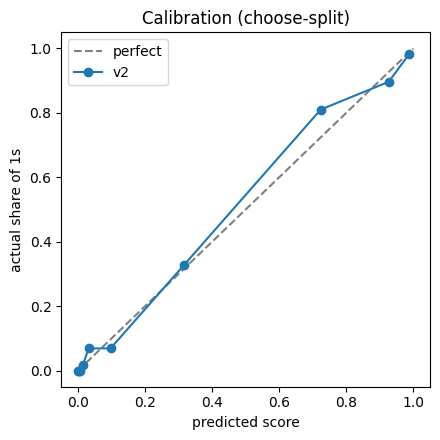

In [28]:
# ---- F6: worst v2 mistakes (new-rule label where decided, else old)
err_sets = []
for name, df in EVAL.items():
    d = df.assign(set=name, y=best_label(df), label_source=np.where(df["label_new"].notna(), "new", "old"))
    if "category" not in d:
        d["category"] = d.get("topic", "")
    err_sets.append(d[["set", "text", "y", "label_source", "score_v2", "keyword", "category"]
                      + (["score_v1"] if "v1" in MODELS else [])])
errs = pd.concat(err_sets)
errs["error"] = (errs["score_v2"] - errs["y"]).abs()
worst = errs[errs["error"] >= 0.5].sort_values("error", ascending=False).head(25)
print("F6. Worst v2 mistakes")
with pd.option_context("display.max_colwidth", 120):
    display(worst)
worst.to_csv(out("F_errors.csv"), index=False)

# ---- F7: calibration plot (choose-split was not used to fit the calibration)
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
if os.path.exists(out("E_choose_split.csv")):
    cs = pd.read_csv(out("E_choose_split.csv"))
    frac, mean_p = calibration_curve(cs["label"], cs["score"], n_bins=10, strategy="quantile")
    plt.figure(figsize=(4.5, 4.5))
    plt.plot([0, 1], [0, 1], "--", color="grey", label="perfect")
    plt.plot(mean_p, frac, "o-", label="v2")
    plt.xlabel("predicted score"); plt.ylabel("actual share of 1s"); plt.title("Calibration (choose-split)")
    plt.legend(); plt.tight_layout()
    plt.savefig(out("F_calibration.png"), dpi=150)
    plt.show()

## F8. Keyword-dependence test (D.2)
Hide words and score again. If accuracy collapses, the model is a keyword detector. `own top 20` hides each model's own 20 most important content words (common words like the, me, please are not counted); `v1 top 20 hidden` hides v1's words for v2 too, so both are tested on the same sentences; `all money words removed` deletes every word from the keyword list (pay, OTP, fee, $…) from the raw text.

In [29]:
# ---- F8: keyword-dependence test (D.2)
# Hide words from the sentences and score again. A model that only spots keywords collapses.
#   own top-N : each model's own top HIDE_TOP_N single words
#   v1 top-N  : v1's top words, hidden for both models (same sentences, same words: the fair comparison)
#   all money words : every strong cue from the keyword list (pay, OTP, fee, $...), removed from the raw text
from money_norm import STRONG_RE, NOT_MONEY_RE

from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

def top_single_words(mdl, n):
    """The model's top content words (no "the", "me", "please"...: hiding those says nothing about keywords)."""
    up, _ = mdl.top_words(300)
    return [w for w, _ in up if " " not in w and not w.endswith("token") and w not in ENGLISH_STOP_WORDS][:n]

def hide_in_clean(mdl, texts, words):
    rx = re.compile(r"\b(?:" + "|".join(map(re.escape, words)) + r")\b") if words else None
    cleaned = [mdl.clean(t) for t in texts]
    return [re.sub(r"\s+", " ", rx.sub(" ", c)).strip() if rx else c for c in cleaned]

def strip_money_words(texts):
    out_ = []
    for t in texts:
        lt = light_norm(t)
        keep = NOT_MONEY_RE.sub(lambda m: m.group(0).replace(" ", "_"), lt)   # protect idioms ("pay attention")
        out_.append(re.sub(r"\s+", " ", STRONG_RE.sub(" ", keep)).replace("_", " ").strip())
    return out_

HIDDEN = {m: top_single_words(mdl, HIDE_TOP_N) for m, mdl in MODELS.items()}
for m, words in HIDDEN.items():
    print(f"{m} top {HIDE_TOP_N} words: {', '.join(words)}")

dep_rows = []
for set_name, df in EVAL.items():
    for rule, col in [("new rule", "label_new"), ("old rule", "label_old")]:
        d = df[df[col].notna()]
        y = d[col].astype(int).to_numpy()
        if len(d) < 20 or len(set(y)) < 2:
            continue
        texts = d["text"].astype(str).tolist()
        for m, mdl in MODELS.items():
            p0 = mdl.predict_proba(texts)
            variants = {"original": p0,
                        f"own top {HIDE_TOP_N} hidden": mdl.predict_proba(hide_in_clean(mdl, texts, HIDDEN[m]), clean=False),
                        "all money words removed": mdl.predict_proba(strip_money_words(texts))}
            if "v1" in HIDDEN and m != "v1":
                variants[f"v1 top {HIDE_TOP_N} hidden"] = mdl.predict_proba(hide_in_clean(mdl, texts, HIDDEN["v1"]), clean=False)
            rec0 = (p0[y == 1] >= THRESHOLD).mean()
            for v, p in variants.items():
                rec = (p[y == 1] >= THRESHOLD).mean()
                dep_rows.append({"set": set_name, "labels": rule, "model": m, "version": v, "n": len(y),
                                 "roc_auc": round(roc_auc_score(y, p), 3), "recall_1s": round(rec, 3),
                                 "recall_kept": round(rec / rec0, 2) if rec0 > 0 else np.nan})
        break   # new-rule labels if there are enough, otherwise old-rule

dep = pd.DataFrame(dep_rows)
if len(dep):
    hid = dep[dep["version"].str.contains("own top")]
    dep_pass = hid.assign(passes=(hid["roc_auc"] >= HIDDEN_AUC_MIN) & (hid["recall_kept"].fillna(0) >= HIDDEN_RECALL_KEEP))
    print(f"\nF8. Keyword dependence. Pass = ROC-AUC >= {HIDDEN_AUC_MIN} and recall kept >= {HIDDEN_RECALL_KEEP} "
          f"with the model's own top {HIDE_TOP_N} words hidden")
    with pd.option_context("display.width", 200):
        display(dep)
        display(dep_pass[["set", "labels", "model", "roc_auc", "recall_kept", "passes"]])
    dep.to_csv(out("F_keyword_dependence.csv"), index=False)
    results_all["keyword_dependence"] = dep.to_dict("records")
else:
    dep_pass = pd.DataFrame()
    print("F8. Not enough labelled sentences to run the keyword-dependence test")

v1 top 20 words: fee, refund, money, price, pay, paid, cost, payment, card, premium, cash, purchase, prices, savings, tax, loan, account, gift, salary, credit
v2 top 20 words: pay, read, transfer, send, account, number, code, request, money, payment, deposit, funds, numbers, confirm, just, release, text, withdraw, required, provide

F8. Keyword dependence. Pass = ROC-AUC >= 0.75 and recall kept >= 0.5 with the model's own top 20 words hidden


,set,labels,model,version,n,roc_auc,recall_1s,recall_kept
0,SG gold,new rule,v1,original,60,0.808,0.824,1.00
1,SG gold,new rule,v1,own top 20 hidden,60,0.767,0.471,0.57
2,SG gold,new rule,v1,all money words removed,60,0.661,0.412,0.50
3,SG gold,new rule,v2,original,60,0.938,0.706,1.00
4,SG gold,new rule,v2,own top 20 hidden,60,0.925,0.588,0.83
5,SG gold,new rule,v2,all money words removed,60,0.926,0.588,0.83
6,SG gold,new rule,v2,v1 top 20 hidden,60,0.936,0.647,0.92
7,Test set,new rule,v1,original,200,0.802,0.936,1.00
8,Test set,new rule,v1,own top 20 hidden,200,0.785,0.851,0.91
9,Test set,new rule,v1,all money words removed,200,0.703,0.319,0.34


,set,labels,model,roc_auc,recall_kept,passes
1,SG gold,new rule,v1,0.767,0.57,True
4,SG gold,new rule,v2,0.925,0.83,True
8,Test set,new rule,v1,0.785,0.91,True
11,Test set,new rule,v2,0.956,0.61,True
15,FTC,new rule,v1,0.741,0.11,False
18,FTC,new rule,v2,0.954,1.00,True


## F9, F10. Probes and demo calls
`probes.csv` columns: `text,label,category`. Categories used by the goals in F11: `mention`, `anti_scam`, `idiom`, `receipt`, `refusal`, `fact` (all 0) and `ask_no_keyword`, `ask_keyword` (1). Probes must be written by a person who did not write the training rows.

`demo_calls_en.csv` columns: `call_id,label,seq,speaker,text` (label 1 = scam call). These are the app's demo scripts, the same calls the team's replay test plays.

In [30]:
# ---- F9: probes (hand-written test sentences, never trained on)
probe_table = None
if probes is not None:
    pr = score_all(probes.copy())
    rows = []
    for cat, g in pr.groupby("category"):
        r = {"category": cat, "n": len(g), "label": int(g["label"].iloc[0]) if g["label"].nunique() == 1 else "mixed"}
        for m in MODELS:
            r[f"{m}_correct_pct"] = round(100 * ((g[f"score_{m}"] >= THRESHOLD).astype(int) == g["label"]).mean())
            r[f"{m}_mean_score"] = round(g[f"score_{m}"].mean(), 2)
        r["keyword_correct_pct"] = round(100 * (g["keyword"] == g["label"]).mean())
        rows.append(r)
    probe_table = pd.DataFrame(rows)
    print("F9. Probes per category")
    display(probe_table)
    with pd.option_context("display.max_colwidth", 100):
        wrong = pr[(pr["score_v2"] >= THRESHOLD).astype(int) != pr["label"]]
        print(f"v2 wrong on {len(wrong)} of {len(pr)} probes:")
        display(wrong[["category", "label", "text", "score_v2"] + (["score_v1"] if "v1" in MODELS else [])])
    pr.to_csv(out("F_probes_scored.csv"), index=False)
    results_all["probes"] = probe_table.to_dict("records")
else:
    print("F9. probes.csv not found in the main folder: probe test skipped")

# ---- F10: demo calls. Highest score over the caller's sentences, as the live worker does (score_chunk per line)
demo_table = None
if demo_calls is not None:
    rows = []
    for (cid, lab), g in demo_calls[demo_calls["speaker"] == "caller"].groupby(["call_id", "label"]):
        r = {"call_id": cid, "type": "scam" if lab == 1 else "normal"}
        for m, mdl in MODELS.items():
            best = max((mdl.score_chunk(t) for t in g["text"]), key=lambda x: x[0])
            r[f"{m}_max"] = round(best[0], 3)
            r[f"{m}_over_line"] = best[0] >= MONEY_RULE_LINE
            r[f"{m}_sentence"] = best[1][:80]
        rows.append(r)
    demo_table = pd.DataFrame(rows).sort_values(["type", "call_id"])
    print(f"\nF10. Demo calls: highest money score per call (aggregator money-rule line = {MONEY_RULE_LINE})")
    with pd.option_context("display.max_colwidth", 80, "display.width", 220):
        display(demo_table)
    for m in MODELS:
        n_norm = demo_table[demo_table["type"] == "normal"]
        n_scam = demo_table[demo_table["type"] == "scam"]
        print(f"  {m}: normal calls over the line {int(n_norm[f'{m}_over_line'].sum())}/{len(n_norm)}, "
              f"scam calls over the line {int(n_scam[f'{m}_over_line'].sum())}/{len(n_scam)}")
    demo_table.to_csv(out("F_demo_calls.csv"), index=False)
    results_all["demo_calls"] = demo_table.to_dict("records")
else:
    print("F10. demo_calls_en.csv not found in the main folder: demo-call test skipped")

F9. probes.csv not found in the main folder: probe test skipped
F10. demo_calls_en.csv not found in the main folder: demo-call test skipped


# Part G: The 200-sentence test set in detail

In [31]:
# ---- G: the 200-sentence test set in detail (v2; new-rule label where decided, else old)
from sklearn.metrics import confusion_matrix
t = tset.assign(y=best_label(tset))
print(f"G. {len(t)} test sentences, {int(t['label_new'].notna().sum())} with a new-rule label")

# leakage check: is any test sentence (almost) in the training data?
vec = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True).fit(train["text_clean"])
sim = (vec.transform(t["text"].map(clean_text)) @ vec.transform(train["text_clean"]).T).max(axis=1).toarray().ravel()
t["seen_in_training"] = sim >= NEAR_DUP_THRESHOLD
print(f"Leakage check: {int(t['seen_in_training'].sum())} test sentences are >= {NEAR_DUP_THRESHOLD} similar to training data")

t["pred"] = (t["score_v2"] >= THRESHOLD).astype(int)
tn, fp, fn, tp = confusion_matrix(t["y"], t["pred"], labels=[0, 1]).ravel()
print(f"\nG2. v2 confusion matrix at threshold {THRESHOLD}")
display(pd.DataFrame([[tn, fp], [fn, tp]], index=["actual 0", "actual 1"], columns=["predicted 0", "predicted 1"]))
print(f"accuracy = {(tp + tn) / len(t):.3f}   false-alarm rate = {fp / max(fp + tn, 1):.3f}   miss rate = {fn / max(fn + tp, 1):.3f}")

sweep = pd.DataFrame([{"threshold": th, **metrics_at(t["y"], t["score_v2"], th)} for th in (0.3, 0.4, 0.5, 0.6, 0.7)])
print("\nG4. v2 threshold sweep")
display(sweep)

errs_g = t[t["pred"] != t["y"]].assign(error=lambda d: (d["score_v2"] - d["y"]).abs()).sort_values("error", ascending=False)
show = [c for c in ("text", "y", "score_v2", "score_v1", "keyword", "category", "call_type") if c in errs_g.columns]
with pd.option_context("display.max_colwidth", 110):
    print(f"\nG5. v2 false alarms (0 scored high): {int(fp)} total, worst 15")
    display(errs_g[errs_g["y"] == 0][show].head(15))
    print(f"G5. v2 misses (1 scored low): {int(fn)} total, worst 15")
    display(errs_g[errs_g["y"] == 1][show].head(15))
t.to_csv(out("G_test_set_scored.csv"), index=False)
errs_g[show].to_csv(out("G_test_set_errors.csv"), index=False)

G. 200 test sentences, 200 with a new-rule label
Leakage check: 1 test sentences are >= 0.9 similar to training data

G2. v2 confusion matrix at threshold 0.5


,predicted 0,predicted 1
actual 0,146,7
actual 1,9,38


accuracy = 0.920   false-alarm rate = 0.046   miss rate = 0.191

G4. v2 threshold sweep


,threshold,precision,recall,f1
0,0.3,0.759,0.936,0.838
1,0.4,0.820,0.872,0.845
2,0.5,0.844,0.809,0.826
3,0.6,0.884,0.809,0.844
4,0.7,0.897,0.745,0.814



G5. v2 false alarms (0 scored high): 7 total, worst 15


,text,y,score_v2,score_v1,keyword,category,call_type
37,Top up your cash card with $20 before driving through the ERP gantry later.,0,0.843738,1.000000,1,payment_request,legit
103,Can you send me the slide presentation deck before our weekly team meeting?,0,0.818384,0.002167,0,everyday,legit
142,I need to transfer these potted plants to bigger garden pots today.,0,0.810378,0.033017,0,word_sense,legit
132,You should pay heed to the doctor's advice and get sufficient rest.,0,0.740273,0.888025,0,word_sense,legit
33,Please settle your outstanding credit card balance of $450 before the due date.,0,0.655403,1.000000,1,payment_request,legit
124,Can you pass me the salt and pepper shaker across the table?,0,0.579707,0.001181,0,word_sense,legit
24,Can you pay the courier twenty dollars in cash upon delivery of your parcel?,0,0.512160,0.999999,1,payment_request,legit


G5. v2 misses (1 scored low): 9 total, worst 15


,text,y,score_v2,score_v1,keyword,category,call_type
46,We need your full bank account number linked to your NRIC for loan approval.,1,0.086327,0.999998,1,card_bank_details,scam
3,"Sir, I need you to authorize the login push notification on your Singpass app right now.",1,0.215126,0.113599,0,otp_request,scam
17,Kindly settle your unpaid Singtel invoice of eighty dollars before midnight to avoid line disconnection.,1,0.282002,0.999724,1,payment_request,legit
94,You need to clear your outstanding dues with us by the end of today.,1,0.321390,0.042620,0,hard_one,scam
38,You need to make a security deposit of 2k for the apartment rental unit.,1,0.327314,0.983636,1,payment_request,legit
12,Kindly state the four-digit security code received on your handset to verify this call.,1,0.350802,0.971834,1,otp_request,legit
32,Kindly transfer fifty dollars to my UOB savings account for the group gift.,1,0.437667,1.000000,1,payment_request,legit
30,Send three hundred bucks via PayNow to reserve the concert tickets before they sell out.,1,0.452131,0.956355,1,payment_request,legit
25,"Please clear the S$1,200 fine immediately to prevent legal action from government agencies.",1,0.461917,0.776107,1,payment_request,scam


## F11. Before / after (D.6)
One row per goal, v1 next to v2. Save `before_after.csv` for the report. Run this again after `recheck_labelled.csv` is filled in: until then the test-set rows use the old rule's labels.

In [32]:
# ---- F11: before/after table (D.6) and the goals
def pick(set_name, method, metric, rule=None):
    d = f1_table[(f1_table["set"] == set_name) & (f1_table["method"] == method)]
    if rule is None:   # prefer new-rule numbers when that set has both classes under the new rule
        newer = d[(d["labels"] == "new rule") & d["roc_auc"].notna()]
        d = newer if len(newer) else d[d["labels"] == "old rule"]
    else:
        d = d[d["labels"] == rule]
    return (float(d[metric].iloc[0]), d["labels"].iloc[0]) if len(d) else (np.nan, "-")

goals = []
def goal(name, metric_fn, target, check):
    row = {"goal": name, "target": target}
    for m in MODELS:
        v, note = metric_fn(m)
        row[m] = v
        row[f"{m}_pass"] = (bool(check(v)) if not (isinstance(v, float) and np.isnan(v)) else None)
        row["labels"] = note
    goals.append(row)

for set_name in EVAL:
    goal(f"{set_name}: ROC-AUC", lambda m, s=set_name: pick(s, f"model {m}", "roc_auc"), ">= 0.85", lambda v: v >= 0.85)
    goal(f"{set_name}: F1 @{THRESHOLD}", lambda m, s=set_name: pick(s, f"model {m}", "f1"), "> keyword list F1",
         lambda v, s=set_name: v > pick(s, "keyword list", "f1")[0])
    goal(f"{set_name}: false-alarm rate on 0s", lambda m, s=set_name: pick(s, f"model {m}", "false_alarm_rate"), "<= 0.10",
         lambda v: v <= 0.10)

if len(dep_pass):
    for set_name in dep_pass["set"].unique():
        goal(f"{set_name}: ROC-AUC with own top {HIDE_TOP_N} words hidden",
             lambda m, s=set_name: (float(dep_pass[(dep_pass["set"] == s) & (dep_pass["model"] == m)]["roc_auc"].iloc[0]),
                                    dep_pass[dep_pass["set"] == s]["labels"].iloc[0])
             if len(dep_pass[(dep_pass["set"] == s) & (dep_pass["model"] == m)]) else (np.nan, "-"),
             f">= {HIDDEN_AUC_MIN}", lambda v: v >= HIDDEN_AUC_MIN)

if probe_table is not None:
    def probe_pct(m, cats):
        g = probe_table[probe_table["category"].isin(cats)]
        return (float((g[f"{m}_correct_pct"] * g["n"]).sum() / g["n"].sum()) if len(g) else np.nan, "probes")
    MENTION_CATS = ["mention", "anti_scam", "idiom", "receipt", "refusal", "fact"]
    goal("Probes: money word but no ask, NOT flagged (%)", lambda m: probe_pct(m, MENTION_CATS), ">= 85", lambda v: v >= 85)
    goal("Probes: ask without the usual keywords, caught (%)", lambda m: probe_pct(m, ["ask_no_keyword"]), ">= 70", lambda v: v >= 70)
    goal("Probes: clear ask with keywords, caught (%)", lambda m: probe_pct(m, ["ask_keyword"]), ">= 90", lambda v: v >= 90)

if demo_table is not None:
    n_norm = demo_table[demo_table["type"] == "normal"]
    n_scam = demo_table[demo_table["type"] == "scam"]
    goal(f"Demo calls: normal calls below {MONEY_RULE_LINE}", lambda m: (float((~n_norm[f"{m}_over_line"]).sum()), "demo"),
         f">= {len(n_norm) - 1} of {len(n_norm)}", lambda v: v >= len(n_norm) - 1)
    goal(f"Demo calls: scam calls at or above {MONEY_RULE_LINE}", lambda m: (float(n_scam[f"{m}_over_line"].sum()), "demo"),
         f"{len(n_scam)} of {len(n_scam)}", lambda v: v >= len(n_scam))

ks_path = out("C_keyword_check.json")
if os.path.exists(ks_path):
    ks = json.load(open(ks_path))
    goals.append({"goal": "Training data: % of 0s with a money word", "target": ">= 5", "labels": "training",
                  "v2": ks["pct_0s_with_money_word"], "v2_pass": ks["pct_0s_with_money_word"] >= 5,
                  **({"v1": 0.0, "v1_pass": False} if "v1" in MODELS else {})})
    goals.append({"goal": "Training data: % of 1s without a money word", "target": ">= 5", "labels": "training",
                  "v2": ks["pct_1s_without_money_word"], "v2_pass": ks["pct_1s_without_money_word"] >= 5,
                  **({"v1": 0.0, "v1_pass": False} if "v1" in MODELS else {})})

before_after = pd.DataFrame(goals)
order = ["goal", "target", "labels"] + [c for m in MODELS for c in (m, f"{m}_pass")]
before_after = before_after[[c for c in order if c in before_after.columns]]
print("F11. Before / after (D.6). 'labels' says which labels the row used: new rule once the recheck sheet is done.")
with pd.option_context("display.width", 220, "display.max_colwidth", 70):
    display(before_after)
before_after.to_csv(out("before_after.csv"), index=False)
n_pass = int(before_after["v2_pass"].fillna(False).astype(bool).sum())
print(f"\nv2 passes {n_pass} of {int(before_after['v2_pass'].notna().sum())} goals")
if not load_recheck():
    print("NOTE: recheck_labelled.csv is not filled in yet, so the test-set rows use OLD-rule labels, which v1 was built for. "
          "Fill in the recheck sheet and re-run Part F for the real comparison.")

# eval scores next to the frozen model (the model and its card are never rewritten)
results_all["before_after"] = before_after.to_dict("records")
json.dump(results_all, open(out("F_results.json"), "w"), indent=2, default=str)
json.dump({"version": MODEL_VERSION, "evaluated": pd.Timestamp.now().isoformat(timespec="seconds"),
           "recheck_labels_used": len(load_recheck()), "before_after": before_after.to_dict("records")},
          open(os.path.join(MODEL_DIR, f"{MODEL_VERSION}_eval.json"), "w"), indent=2, default=str)

print(f"""
Copy into backend/workers/money_en/ in the repo:
  from {CODE_DIR}:  money_norm.py, money_model.py, train.py, LABELING.md
  from {MODEL_DIR}: {MODEL_VERSION}.joblib, {MODEL_VERSION}.json, {MODEL_VERSION}_eval.json   (into model/)
  from {OUT_DIR}:  C_train_pool.csv (into data/, so train.py can be re-run), before_after.csv
Keep model/E_model.joblib (v1) as it is, and add a small model/money_en_v1.json describing it.
Then change E_model.joblib -> {MODEL_VERSION}.joblib in Dockerfile and predict.py, and re-run the team's replay test.""")

F11. Before / after (D.6). 'labels' says which labels the row used: new rule once the recheck sheet is done.


,goal,target,labels,v1,v1_pass,v2,v2_pass
0,SG gold: ROC-AUC,>= 0.85,new rule,0.808,False,0.938,True
1,SG gold: F1 @0.5,> keyword list F1,new rule,0.609,False,0.750,True
2,SG gold: false-alarm rate on 0s,<= 0.10,new rule,0.349,False,0.070,True
3,Test set: ROC-AUC,>= 0.85,new rule,0.802,False,0.977,True
4,Test set: F1 @0.5,> keyword list F1,new rule,0.615,False,0.826,True
5,Test set: false-alarm rate on 0s,<= 0.10,new rule,0.340,False,0.046,True
6,FTC: ROC-AUC,>= 0.85,new rule,0.763,False,0.954,True
7,FTC: F1 @0.5,> keyword list F1,new rule,0.047,True,0.400,True
8,FTC: false-alarm rate on 0s,<= 0.10,new rule,0.233,False,0.010,True
9,SG gold: ROC-AUC with own top 20 words hidden,>= 0.75,new rule,0.767,True,0.925,True



v2 passes 14 of 14 goals

Copy into backend/workers/money_en/ in the repo:
  from /content/drive/MyDrive/CSC3104_money_otp/code:  money_norm.py, money_model.py, train.py, LABELING.md
  from /content/drive/MyDrive/CSC3104_money_otp/model: money_en_v2c.joblib, money_en_v2c.json, money_en_v2c_eval.json   (into model/)
  from /content/drive/MyDrive/CSC3104_money_otp/processed:  C_train_pool.csv (into data/, so train.py can be re-run), before_after.csv
Keep model/E_model.joblib (v1) as it is, and add a small model/money_en_v1.json describing it.
Then change E_model.joblib -> money_en_v2c.joblib in Dockerfile and predict.py, and re-run the team's replay test.
